# Классификация технологических данных по степени критичности для приоритизации их передачи в распределённых системах мониторинга

**Курсовая работа** · Датасет: **Petrobras 3W** (Parquet) · https://github.com/petrobras/3W

**Идея:** модель классифицирует состояние скважины по показаниям датчиков, затем состояние переводится в уровень критичности **P0–P3**, а уровень определяет политику передачи (очередь, QoS).

**Как запустить:**
1. `git clone https://github.com/petrobras/3W` (или скачать папку `dataset`)
2. Установить зависимости: `pip install pandas numpy scikit-learn matplotlib seaborn pyarrow`
3. Указать путь к папке `dataset` в переменной `PATH_3W` (ячейка 2) и выполнить все ячейки

Для первого прогона удобно поставить `MAX_FILES_PER_CLASS = 30` — загрузка займёт секунды. Потом поставить `None` и пересчитать на всём датасете.

## 0. Зависимости


In [1]:
# %pip install pandas numpy scikit-learn matplotlib seaborn pyarrow catboost imbalanced-learn

## 1. Импорт библиотек

In [2]:
import os, glob, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score, recall_score)

import copy
import warnings
warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams["figure.dpi"] = 110


## 2. Параметры и соответствие «тип события → уровень критичности»

В 3W название подпапки (`0`…`9`) — это тип события. Укрупняем 10 типов до 4 уровней критичности.

In [3]:
# ───────── ПАРАМЕТРЫ ─────────
PATH_3W = "./3W-main/dataset"      # путь к папке dataset (внутри неё подпапки 0..9)
SOURCES = ("WELL", "SIMULATED", "DRAWN")   # реальные скважины / симуляции / нарисованные экспертом
MAX_FILES_PER_CLASS = None      # None = все файлы (для финального прогона); 30 = быстрый тест
RESAMPLE = "1min"             # данные 1 Гц усредняем до 1 минуты
ROLL_WINDOW = 10              # окно (в минутах) для скользящего СКО (ловит нестабильность/слаггинг)
MAX_NAN_SHARE = 0.30          # датчики с долей пропусков больше этого порога отбрасываем
MAX_TRAIN_ROWS = 300_000      # ограничение размера обучающей выборки (скорость)
GROUP_BY = "group"            # разбиение по скважинам ("group") или по эпизодам-файлам ("file")
LAGS = (5, 15)                # разности x(t) - x(t-k), мин (тренд); () — не вычислять
USE_LAGS = False              # True — включить разностные признаки в основные модели

# ───────── Типы событий и уровни критичности ─────────
EVENT_NAMES = {
    0: "Normal Operation",            1: "Abrupt Increase of BSW",
    2: "Spurious Closure of DHSV",    3: "Severe Slugging",
    4: "Flow Instability",            5: "Rapid Productivity Loss",
    6: "Quick Restriction in PCK",    7: "Scaling in PCK",
    8: "Hydrate in Production Line",  9: "Hydrate in Service Line",
}
CLASS_TO_PRIORITY = {0: 0,            # норма                      -> P0
                     1: 1, 7: 1,      # BSW, отложения в штуцере   -> P1
                     4: 2, 5: 2, 6: 2,# нестабильность, потеря продуктивности, ограничение -> P2
                     2: 3, 3: 3, 8: 3, 9: 3}  # DHSV, слаггинг, гидраты -> P3

PRIORITY_NAMES = {0: "P0 — фоновый", 1: "P1 — обычный",
                  2: "P2 — повышенный", 3: "P3 — критический"}
CLASS_NAMES = list(PRIORITY_NAMES.values())
COLORS_P = ["#4CAF50", "#2196F3", "#FF9800", "#F44336"]

## 3. Загрузка датасета 3W (Parquet)

Структура: `dataset/<0..9>/<файл>.parquet`, один файл = один экземпляр (одна скважина/эпизод), время в индексе, метка в столбце `class`.
Имя файла показывает источник: `WELL-…` (реальная скважина), `SIMULATED_…`, `DRAWN_…`.

Что делает загрузчик для каждого файла:
1. читает parquet и приводит типы `Float64`/`Int64` к обычным `float64`;
2. усредняет 1 Гц → 1 минута (как и принято работать с 3W);
3. добавляет скользящее СКО (`*_std`) — по среднему значению нестабильность потока и слаггинг не поймать;
4. оставляет только устоявшиеся состояния (`class` < 100), переходные участки (101…109) отбрасывает.

In [4]:
assert os.path.isdir(PATH_3W), (f"Папка {PATH_3W!r} не найдена. Скачайте репозиторий 3W "
                                f"и укажите путь к папке dataset в PATH_3W.")

def list_instances(path):
    items = []
    for fp in sorted(glob.glob(os.path.join(path, "*", "*.parquet"))):
        folder = os.path.basename(os.path.dirname(fp))
        if not folder.isdigit():
            continue
        name = os.path.basename(fp)
        source = name.split("_")[0].split("-")[0].upper()          # WELL / SIMULATED / DRAWN
        group = name.split("_")[0] if source == "WELL" else os.path.splitext(name)[0]
        items.append(dict(path=fp, folder=int(folder), source=source, group=group, file=name))
    return pd.DataFrame(items)

inst = list_instances(PATH_3W)
assert len(inst) > 0, "Parquet-файлы не найдены (ожидается dataset/<0..9>/*.parquet)"
inst = inst[inst["source"].isin(SOURCES)]

print("Экземпляров в датасете (до отбора): папка × источник")
display(pd.crosstab(inst["folder"], inst["source"], margins=True))

if MAX_FILES_PER_CLASS:
    inst = (inst.sample(frac=1, random_state=42)      # перемешиваем
                .groupby("folder").head(MAX_FILES_PER_CLASS)   # первые N файлов в каждом классе
                .sort_index())
print(f"\nБудет загружено файлов: {len(inst)}")

Экземпляров в датасете (до отбора): папка × источник


source,DRAWN,SIMULATED,WELL,All
folder,,,,
0,0,0,594,594
1,10,114,4,128
2,0,16,22,38
3,0,74,32,106
4,0,0,343,343
5,0,439,11,450
6,0,215,6,221
7,10,0,36,46
8,0,81,14,95



Будет загружено файлов: 2228


In [5]:
def load_instance(row):
    df = pd.read_parquet(row["path"])
    df.index = pd.to_datetime(df.index)
    # Float64/Int64 (nullable) -> обычный float64 с NaN
    df = pd.DataFrame(df.to_numpy(dtype="float64", na_value=np.nan),
                      index=df.index, columns=df.columns)
    df.columns = [c.replace("-", "_") for c in df.columns]
    if "class" not in df.columns:
        return None

    # только датчики: без метки, state и дискретных состояний клапанов (ESTADO_*)
    sensors = [c for c in df.columns if c not in ("class", "state") and not c.startswith("ESTADO")]

    agg = df[sensors].resample(RESAMPLE).mean().ffill()           # 1 Гц -> 1 мин, закрываем дыры
    means = agg
    if ROLL_WINDOW:
        std = agg.rolling(ROLL_WINDOW, min_periods=3).std().add_suffix("_std")
        agg = agg.join(std)
    for k in LAGS:                                                # разности за k минут (тренд), внутри файла
        agg = agg.join((means - means.shift(k)).add_suffix(f"_d{k}"))
    agg["class"] = df["class"].resample(RESAMPLE).last()

    agg = agg.dropna(subset=["class"])
    agg = agg[agg["class"] < 100]                                 # убираем переходные участки (101..109)
    agg = agg[agg["class"].isin(CLASS_TO_PRIORITY.keys())]
    if agg.empty:
        return None

    agg["event_folder"] = row["folder"]
    agg["source"] = row["source"]
    agg["group"] = row["group"]
    agg["file"] = row["file"]
    return agg.astype({c: "float32" for c in agg.columns if agg[c].dtype == np.float64})

parts, t0 = [], time.time()
for i, (_, row) in enumerate(inst.iterrows(), 1):
    part = load_instance(row)
    if part is not None:
        parts.append(part)
    if i % 200 == 0:
        print(f"  обработано {i}/{len(inst)} файлов ({time.time()-t0:.0f} c)")

df = pd.concat(parts, ignore_index=True)
df["priority"] = df["class"].map(CLASS_TO_PRIORITY).astype(int)
print(f"\nГотово за {time.time()-t0:.0f} c. Строк (минутных наблюдений): {len(df):,}")
print("Метки class в данных (проверка соглашения о метках):", [int(c) for c in sorted(df["class"].unique())])

  обработано 200/2228 файлов (11 c)
  обработано 400/2228 файлов (20 c)
  обработано 600/2228 файлов (29 c)
  обработано 800/2228 файлов (43 c)
  обработано 1000/2228 файлов (52 c)
  обработано 1200/2228 файлов (61 c)
  обработано 1400/2228 файлов (74 c)
  обработано 1600/2228 файлов (85 c)
  обработано 1800/2228 файлов (95 c)
  обработано 2000/2228 файлов (110 c)
  обработано 2200/2228 файлов (125 c)

Готово за 129 c. Строк (минутных наблюдений): 775,325
Метки class в данных (проверка соглашения о метках): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 4. Отбор признаков

В 3W не все датчики есть на всех скважинах — часть столбцов в ряде файлов пустая. Считаем долю пропусков и оставляем датчики, которые присутствуют достаточно часто.

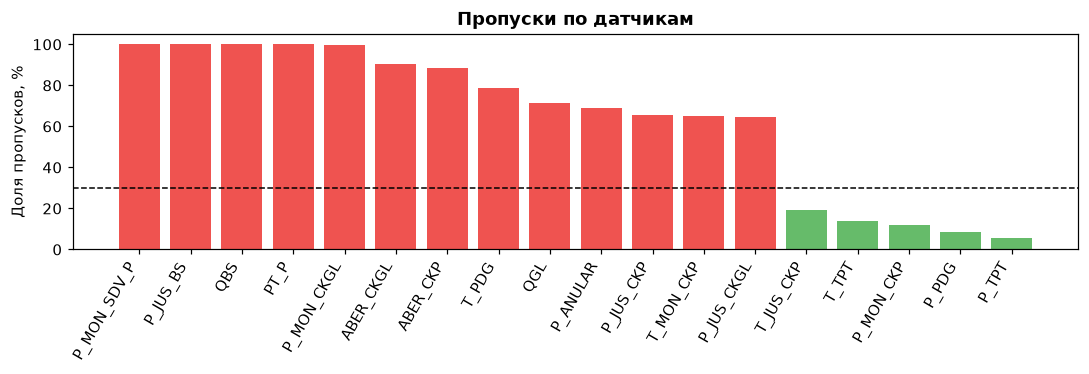

Датчиков оставлено: 5 из 18
Признаки: ['P_MON_CKP', 'P_PDG', 'P_TPT', 'T_JUS_CKP', 'T_TPT', 'P_MON_CKP_std', 'P_PDG_std', 'P_TPT_std', 'T_JUS_CKP_std', 'T_TPT_std']


In [6]:
import re
META_COLS = ["class", "priority", "event_folder", "source", "group", "file"]
is_aux = lambda c: c.endswith("_std") or re.search(r"_d\d+$", c) is not None   # СКО и разности
BASE_COLS = [c for c in df.columns if c not in META_COLS and not is_aux(c)]

nan_share = df[BASE_COLS].isna().mean().sort_values(ascending=False)
KEEP = [c for c in BASE_COLS if nan_share[c] <= MAX_NAN_SHARE]
BASE_FEATURES = KEEP + [c + "_std" for c in KEEP if c + "_std" in df.columns]          # средние + СКО
LAG_COLS = [f"{c}_d{k}" for k in LAGS for c in KEEP if f"{c}_d{k}" in df.columns]      # разности
FEATURE_COLS = BASE_FEATURES + (LAG_COLS if USE_LAGS else [])

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(nan_share.index, nan_share.values * 100,
       color=["#EF5350" if v > MAX_NAN_SHARE else "#66BB6A" for v in nan_share.values])
ax.axhline(MAX_NAN_SHARE * 100, color="k", ls="--", lw=1)
ax.set_ylabel("Доля пропусков, %"); ax.set_title("Пропуски по датчикам", fontweight="bold")
plt.xticks(rotation=60, ha="right"); plt.tight_layout(); plt.show()

print(f"Датчиков оставлено: {len(KEEP)} из {len(BASE_COLS)}")
print("Признаки:", FEATURE_COLS)

In [7]:
# Диагностика: доля пропусков и покрытие по источникам
nan_table = pd.DataFrame({
    "доля_NaN_%": (nan_share * 100).round(1),
    "есть в WELL_%":       (df[df.source == "WELL"][nan_share.index].notna().mean() * 100).round(1),
    "есть в SIMULATED_%":  (df[df.source == "SIMULATED"][nan_share.index].notna().mean() * 100).round(1),
    "есть в DRAWN_%":      (df[df.source == "DRAWN"][nan_share.index].notna().mean() * 100).round(1),
    "оставлен": ["да" if c in KEEP else "нет" for c in nan_share.index],
}).sort_values("доля_NaN_%", ascending=False)
display(nan_table)

,доля_NaN_%,есть в WELL_%,есть в SIMULATED_%,есть в DRAWN_%,оставлен
P_MON_SDV_P,100.0,0.0,0.0,0.0,нет
P_JUS_BS,100.0,0.0,0.0,0.0,нет
QBS,100.0,0.0,0.0,0.0,нет
PT_P,100.0,0.0,0.0,0.0,нет
P_MON_CKGL,99.8,0.6,0.0,0.0,нет
ABER_CKGL,90.5,24.7,0.0,0.0,нет
ABER_CKP,88.3,30.4,0.0,0.0,нет
T_PDG,78.8,55.1,0.0,0.0,нет
QGL,71.4,51.5,14.5,0.0,нет
P_ANULAR,69.0,80.6,0.0,0.0,нет


СТРУКТУРА ДАТАСЕТА 3W
Корневая папка: ./3W-main/dataset
Всего подпапок-классов: 10 (0..9)
Всего parquet-файлов (после фильтра источников): 2228

Пример файла: WELL-00001_20170201010207.parquet
  Папка (класс события): 0
  Источник:              WELL
  Группа (скважина/эпизод): WELL-00001

Размер: 21,474 строк × 29 столбцов
Частота: 1 Гц (записей в секунду)
Период: 2017-02-01 01:02:07 — 2017-02-01 07:00:00

Все столбцы файла (29):
['ABER-CKGL', 'ABER-CKP', 'ESTADO-DHSV', 'ESTADO-M1', 'ESTADO-M2', 'ESTADO-PXO', 'ESTADO-SDV-GL', 'ESTADO-SDV-P', 'ESTADO-W1', 'ESTADO-W2', 'ESTADO-XO', 'P-ANULAR', 'P-JUS-BS', 'P-JUS-CKGL', 'P-JUS-CKP', 'P-MON-CKGL', 'P-MON-CKP', 'P-MON-SDV-P', 'P-PDG', 'PT-P', 'P-TPT', 'QBS', 'QGL', 'T-JUS-CKP', 'T-MON-CKP', 'T-PDG', 'T-TPT', 'class', 'state']



,ABER-CKGL,ABER-CKP,ESTADO-DHSV,ESTADO-M1,ESTADO-M2,ESTADO-PXO,ESTADO-SDV-GL,ESTADO-SDV-P,ESTADO-W1,ESTADO-W2,...,PT-P,P-TPT,QBS,QGL,T-JUS-CKP,T-MON-CKP,T-PDG,T-TPT,class,state
timestamp,,,,,,,,,,,,,,,,,,,,,
2017-02-01 01:02:07,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,NaN,10074540.0,NaN,0.0,84.64463,NaN,0.0,119.0781,<NA>,<NA>
2017-02-01 01:02:08,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,NaN,10074540.0,NaN,0.0,84.63828,NaN,0.0,119.0781,<NA>,<NA>
2017-02-01 01:02:09,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,NaN,10074540.0,NaN,0.0,84.63194,NaN,0.0,119.0781,<NA>,<NA>
2017-02-01 01:02:10,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,NaN,10074540.0,NaN,0.0,84.62558,NaN,0.0,119.0781,<NA>,<NA>
2017-02-01 01:02:11,NaN,NaN,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,...,NaN,10074540.0,NaN,0.0,84.61923,NaN,0.0,119.0781,<NA>,<NA>


СВОДКА ПО СТОЛБЦАМ (по всем загруженным файлам)


,count,mean,std,min,25%,50%,75%,max,"NaN, %"
P_TPT,732839.0,15077320.00,48968420.00,-17129300.0,10035344.00,14928380.00,17485312.00,2.941990e+09,5.5
P_TPT_std,730621.0,76928.35,218468.12,0.0,29.36,3784.69,21523.63,5.669507e+06,5.8
P_TPT_d5,727294.0,8466.20,395266.06,-7341225.0,-2494.49,0.00,3193.97,1.415630e+07,6.2
P_TPT_d15,719129.0,25395.15,715448.44,-9722892.0,-8006.17,0.00,6183.24,1.470470e+07,7.2
P_PDG,708402.0,-inf,NaN,-inf,13911357.00,21834820.00,26151452.00,4.853218e+07,8.6
...,...,...,...,...,...,...,...,...,...
PT_P_d5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
P_MON_SDV_P_d5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
P_JUS_BS_d5,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0
QBS_d15,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,100.0


РАЗЛИЧИЯ ПО ИСТОЧНИКАМ


,файлов,наблюдений,средняя_длина_файла,датчиков_с_данными
source,,,,
SIMULATED,439,468708,1067,1
WELL,1119,298466,266,1
DRAWN,10,8151,815,1


Длина эпизода (минут): min=8, median=299, mean=494, max=3905


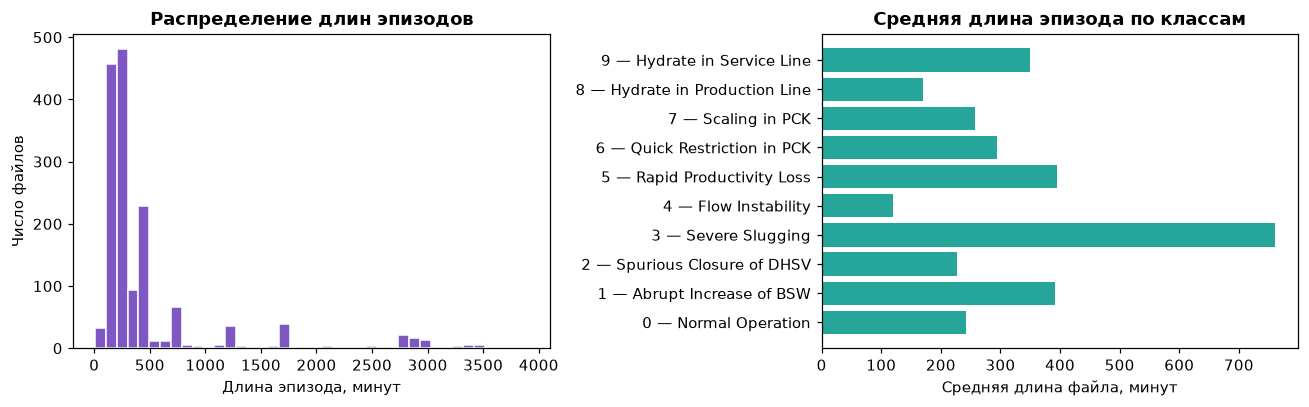

In [8]:
# ═══════════════════════════════════════════════════════════════════════
# Просмотр датасета: структура, примеры, содержимое файлов
# ═══════════════════════════════════════════════════════════════════════

# --- Структура папки dataset ---
print("=" * 70)
print("СТРУКТУРА ДАТАСЕТА 3W")
print("=" * 70)
print(f"Корневая папка: {PATH_3W}")
print(f"Всего подпапок-классов: 10 (0..9)")
print(f"Всего parquet-файлов (после фильтра источников): {len(inst)}")
print()

# --- Что лежит внутри одного файла ---
example_file = inst.iloc[0]
print(f"Пример файла: {example_file['file']}")
print(f"  Папка (класс события): {example_file['folder']}")
print(f"  Источник:              {example_file['source']}")
print(f"  Группа (скважина/эпизод): {example_file['group']}")
print()

raw = pd.read_parquet(example_file["path"])
print(f"Размер: {raw.shape[0]:,} строк × {raw.shape[1]} столбцов")
print(f"Частота: 1 Гц (записей в секунду)")
print(f"Период: {raw.index[0]} — {raw.index[-1]}")
print(f"\nВсе столбцы файла ({raw.shape[1]}):")
print(list(raw.columns))
print()
display(raw.head(5))


# --- Агрегированная сводка по столбцам ---
print("=" * 70)
print("СВОДКА ПО СТОЛБЦАМ (по всем загруженным файлам)")
print("=" * 70)
desc = df.drop(columns=META_COLS, errors="ignore").describe().T
desc["NaN, %"] = (df.drop(columns=META_COLS, errors="ignore").isna().mean() * 100).round(1)
desc = desc[["count", "mean", "std", "min", "25%", "50%", "75%", "max", "NaN, %"]]
desc = desc.round(2).sort_values("NaN, %")
display(desc)


# --- Как устроены разные источники (WELL / SIMULATED / DRAWN) ---
print("=" * 70)
print("РАЗЛИЧИЯ ПО ИСТОЧНИКАМ")
print("=" * 70)
src_stats = df.groupby("source").agg(
    файлов=("file", "nunique"),
    наблюдений=("file", "size"),
    средняя_длина_файла=("file", lambda s: int(len(s) / s.nunique())),
    датчиков_с_данными=("P_MON_CKP", lambda s: int(s.notna().sum() > 0)),
).sort_values("наблюдений", ascending=False)
display(src_stats)


# --- Распределение длин файлов (эпизодов) ---
file_lens = df.groupby("file").size()
print(f"Длина эпизода (минут): min={file_lens.min()}, "
      f"median={int(file_lens.median())}, mean={int(file_lens.mean())}, "
      f"max={file_lens.max()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(file_lens.values, bins=40, color="#7E57C2", edgecolor="white")
axes[0].set_xlabel("Длина эпизода, минут")
axes[0].set_ylabel("Число файлов")
axes[0].set_title("Распределение длин эпизодов", fontweight="bold")

by_class_len = df.groupby("class").size() / df.groupby("class")["file"].nunique()
axes[1].barh([f"{int(c)} — {EVENT_NAMES[int(c)]}" for c in by_class_len.index],
             by_class_len.values, color="#26A69A")
axes[1].set_xlabel("Средняя длина файла, минут")
axes[1].set_title("Средняя длина эпизода по классам", fontweight="bold")
plt.tight_layout(); plt.show()



In [9]:
# ─── Почему столбцов много, а признаков мало: карта заполненности ───
print("=" * 70)
print("КАРТА ЗАПОЛНЕННОСТИ ДАТЧИКОВ ПО ИСТОЧНИКАМ")
print("=" * 70)

base_cols = BASE_COLS   # все 18 базовых датчиков
src_list  = ["WELL", "SIMULATED", "DRAWN"]

coverage = pd.DataFrame(
    {s: df[df["source"] == s][base_cols].notna().mean() * 100 for s in src_list}
).round(1)
coverage["всего_%"] = (df[base_cols].notna().mean() * 100).round(1)
coverage = coverage.sort_values("всего_%", ascending=False)
display(coverage)

# Итог
n_kept   = len(KEEP)
n_all    = len(base_cols)
kept_pct = df[KEEP].notna().mean().mean() * 100
print(f"Итог: из {n_all} датчиков оставлено {n_kept} "
      f"({n_kept/n_all*100:.0f}%); средняя заполненность оставшихся — {kept_pct:.1f}%")

КАРТА ЗАПОЛНЕННОСТИ ДАТЧИКОВ ПО ИСТОЧНИКАМ


,WELL,SIMULATED,DRAWN,всего_%
P_TPT,85.8,100.0,100.0,94.5
P_PDG,77.6,100.0,100.0,91.4
P_MON_CKP,68.8,100.0,100.0,88.0
T_TPT,88.1,84.8,100.0,86.3
T_JUS_CKP,50.1,100.0,100.0,80.8
P_JUS_CKGL,68.7,14.5,0.0,35.2
T_MON_CKP,6.9,53.5,0.0,35.0
P_JUS_CKP,5.8,53.5,0.0,34.6
P_ANULAR,80.6,0.0,0.0,31.0
QGL,51.5,14.5,0.0,28.6


Итог: из 18 датчиков оставлено 5 (28%); средняя заполненность оставшихся — 88.2%


## 5. Анализ данных и предобработка

In [10]:
# Сколько экземпляров (файлов) и наблюдений в каждом классе
summary = (df.groupby("class")
             .agg(файлов=("file", "nunique"), наблюдений=("file", "size"))
             .rename(index=lambda c: f"{int(c)} — {EVENT_NAMES[int(c)]}"))
summary["уровень"] = [PRIORITY_NAMES[CLASS_TO_PRIORITY[int(k.split(' ')[0])]] for k in summary.index]
display(summary)

print("\nЭкземпляры по источникам и уровням критичности:")
display(pd.crosstab(df["source"], df["priority"].map(PRIORITY_NAMES)))

,файлов,наблюдений,уровень
class,,,
0 — Normal Operation,1193,289017,P0 — фоновый
1 — Abrupt Increase of BSW,124,48618,P1 — обычный
2 — Spurious Closure of DHSV,27,6142,P3 — критический
3 — Severe Slugging,106,80677,P3 — критический
4 — Flow Instability,343,41356,P2 — повышенный
5 — Rapid Productivity Loss,446,176327,P2 — повышенный
6 — Quick Restriction in PCK,221,64868,P2 — повышенный
7 — Scaling in PCK,9,2309,P1 — обычный
8 — Hydrate in Production Line,73,12469,P3 — критический



Экземпляры по источникам и уровням критичности:


priority,P0 — фоновый,P1 — обычный,P2 — повышенный,P3 — критический
source,,,,
DRAWN,5890,2261,0,0
SIMULATED,39701,47987,240742,140278
WELL,243426,679,41809,12552


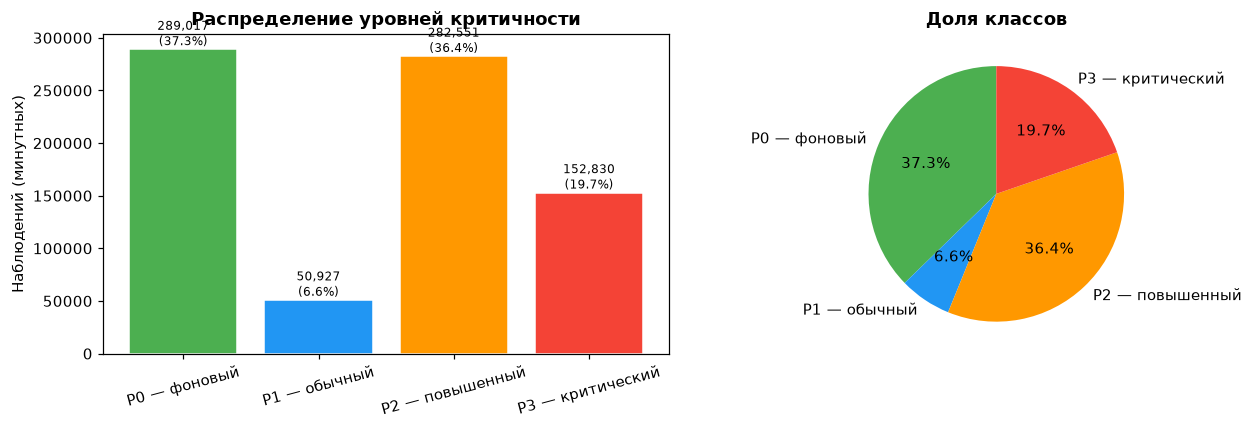

Классы несбалансированы -> class_weight='balanced' и оценка по F1/recall, а не только accuracy


In [11]:
counts = df["priority"].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bars = axes[0].bar([PRIORITY_NAMES[i] for i in counts.index], counts.values,
                   color=COLORS_P, edgecolor="white")
axes[0].set_title("Распределение уровней критичности", fontweight="bold")
axes[0].set_ylabel("Наблюдений (минутных)"); axes[0].tick_params(axis="x", rotation=15)
for b, c in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height(), f"{c:,}\n({c/len(df)*100:.1f}%)",
                 ha="center", va="bottom", fontsize=8)
axes[1].pie(counts.values, labels=[PRIORITY_NAMES[i] for i in counts.index],
            colors=COLORS_P, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Доля классов", fontweight="bold")
plt.tight_layout(); plt.show()
print("Классы несбалансированы -> class_weight='balanced' и оценка по F1/recall, а не только accuracy")

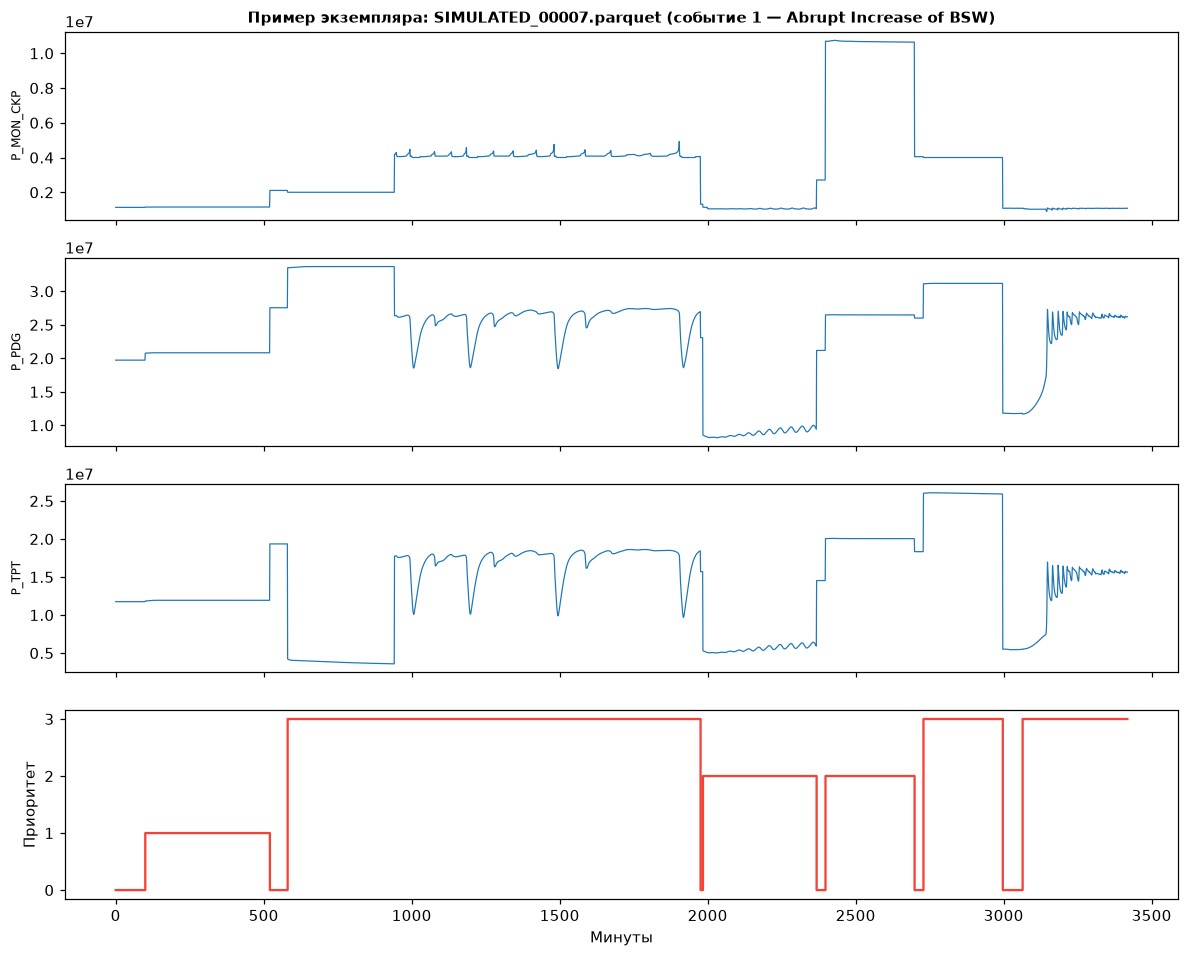

In [12]:
# Пример временных рядов: одна «аварийная» скважина (P3) — как выглядят данные
cand = df[df["priority"] == 3].groupby("file").size().sort_values(ascending=False)
ex_file = cand.index[0]
ex = df[df["file"] == ex_file].reset_index(drop=True)
show = KEEP[:3]

fig, axes = plt.subplots(len(show) + 1, 1, figsize=(11, 2.2 * (len(show) + 1)), sharex=True)
for ax, col in zip(axes[:-1], show):
    ax.plot(ex[col].values, lw=0.8); ax.set_ylabel(col, fontsize=8)
axes[-1].step(range(len(ex)), ex["priority"].values, where="post", color="#F44336")
axes[-1].set_ylabel("Приоритет"); axes[-1].set_yticks([0, 1, 2, 3]); axes[-1].set_xlabel("Минуты")
axes[0].set_title(f"Пример экземпляра: {ex_file} (событие {int(ex['event_folder'].iloc[0])} — "
                  f"{EVENT_NAMES[int(ex['event_folder'].iloc[0])]})", fontweight="bold", fontsize=10)
plt.tight_layout(); plt.show()

In [13]:
# ───────── Что является X и Y ─────────
SENSOR_DESC = {
    "P_PDG":     "давление, стационарный забойный датчик (PDG)",
    "P_TPT":     "давление, датчик TPT на фонтанной арматуре",
    "T_TPT":     "температура, датчик TPT",
    "P_MON_CKP": "давление перед добычным штуцером (PCK)",
    "T_JUS_CKP": "температура за добычным штуцером",
}
xy = pd.DataFrame({
    "признак X": FEATURE_COLS,
    "тип": ["скользящее СКО, 10 мин" if c.endswith("_std") else ("разность за " + c.split("_d")[-1] + " мин")
            if re.search(r"_d\d+$", c) else "среднее за минуту" for c in FEATURE_COLS],
    "что измеряет": [SENSOR_DESC.get(re.sub(r"(_std|_d\d+)$", "", c), "") for c in FEATURE_COLS],
    "пропусков, %": [round(df[c].isna().mean() * 100, 1) for c in FEATURE_COLS],
})
display(xy)
print("Y = priority:", "; ".join(f"{k} = {v}" for k, v in PRIORITY_NAMES.items()))
print(f"N = {len(df):,} наблюдений, d = {len(FEATURE_COLS)} признаков, K = 4 класса")

,признак X,тип,что измеряет,"пропусков, %"
0,P_MON_CKP,среднее за минуту,давление перед добычным штуцером (PCK),12.0
1,P_PDG,среднее за минуту,"давление, стационарный забойный датчик (PDG)",8.6
2,P_TPT,среднее за минуту,"давление, датчик TPT на фонтанной арматуре",5.5
3,T_JUS_CKP,среднее за минуту,температура за добычным штуцером,19.2
4,T_TPT,среднее за минуту,"температура, датчик TPT",13.7
5,P_MON_CKP_std,"скользящее СКО, 10 мин",давление перед добычным штуцером (PCK),12.3
6,P_PDG_std,"скользящее СКО, 10 мин","давление, стационарный забойный датчик (PDG)",8.9
7,P_TPT_std,"скользящее СКО, 10 мин","давление, датчик TPT на фонтанной арматуре",5.8
8,T_JUS_CKP_std,"скользящее СКО, 10 мин",температура за добычным штуцером,19.5
9,T_TPT_std,"скользящее СКО, 10 мин","температура, датчик TPT",14.0


Y = priority: 0 = P0 — фоновый; 1 = P1 — обычный; 2 = P2 — повышенный; 3 = P3 — критический
N = 775,325 наблюдений, d = 10 признаков, K = 4 класса


Порядок по методике: **пропуски и дубли → описательная статистика → выбросы → связь X с Y → мультиколлинеарность X**.
Все ячейки этого раздела только анализируют данные и ничего не меняют в обучающей выборке (кроме необязательного удаления дублей, `DROP_DUPLICATES`).

In [14]:
# ───────── Пропуски и дубли ─────────
DROP_DUPLICATES = False      # True — удалить повторы внутри файла (см. вывод ниже)

miss = df[FEATURE_COLS].isna().sum()
miss_df = pd.DataFrame({"пропусков": miss, "доля, %": (miss / len(df) * 100).round(2)})
print("Пропуски в отобранных признаках:")
display(miss_df.T)
print("Пропуски в *_std — это первые минуты каждого файла: окно скользящего СКО ещё не заполнено "
      "(формула (20) в тексте). Они заполняются медианой обучающей выборки.\n")

dup_all  = df.duplicated(subset=FEATURE_COLS, keep=False)
dup_file = df.duplicated(subset=FEATURE_COLS + ["file"], keep="first")
print(f"Строк с повторяющимся вектором X во всей выборке: {dup_all.sum():,} ({dup_all.mean()*100:.2f}%)")
print(f"Повторов внутри одного файла (без первого вхождения): {dup_file.sum():,} ({dup_file.mean()*100:.2f}%)")
print("\nДоля повторов внутри файла по уровням критичности, %:")
display((dup_file.groupby(df["priority"]).mean() * 100).round(2).rename(index=PRIORITY_NAMES).to_frame("повторов, %").T)

# Одинаковые минутные значения во временном ряду — не обязательно ошибка (датчик не меняется при остановке
# скважины). Поэтому по умолчанию дубли не удаляются; решение принимайте по доле повторов выше.
if DROP_DUPLICATES:
    df = df.loc[~dup_file].reset_index(drop=True)
    print(f"Удалено {dup_file.sum():,} повторов, осталось {len(df):,} наблюдений")

Пропуски в отобранных признаках:


,P_MON_CKP,P_PDG,P_TPT,T_JUS_CKP,T_TPT,P_MON_CKP_std,P_PDG_std,P_TPT_std,T_JUS_CKP_std,T_TPT_std
пропусков,93212.00,66923.00,42486.00,149062.00,106520.00,95430.00,69143.00,44704.00,151280.00,108308.00
"доля, %",12.02,8.63,5.48,19.23,13.74,12.31,8.92,5.77,19.51,13.97


Пропуски в *_std — это первые минуты каждого файла: окно скользящего СКО ещё не заполнено (формула (20) в тексте). Они заполняются медианой обучающей выборки.

Строк с повторяющимся вектором X во всей выборке: 20,220 (2.61%)
Повторов внутри одного файла (без первого вхождения): 18,020 (2.32%)

Доля повторов внутри файла по уровням критичности, %:


priority,P0 — фоновый,P1 — обычный,P2 — повышенный,P3 — критический
"повторов, %",6.14,0.24,0.06,0.0


In [15]:
# ───────── Описательная статистика ─────────
BASE = list(KEEP) # только датчики (без _std)

print("Баланс классов:")
bal = df["priority"].value_counts().sort_index()
display(pd.DataFrame({"наблюдений": bal.values, "доля, %": (bal.values / len(df) * 100).round(1)},
                     index=[PRIORITY_NAMES[i] for i in bal.index]).T)

print("Общая статистика датчиков:")
gen = df[BASE].describe().T
gen["асимметрия"] = df[BASE].skew(); gen["эксцесс"] = df[BASE].kurt()
display(gen.round(2))

print("Статистика датчиков по уровням критичности:")
by_cls = df.groupby("priority")[BASE].agg(["mean", "std", "min", "median", "max"]).round(2)
by_cls.index = [PRIORITY_NAMES[i] for i in by_cls.index]
display(by_cls)

Баланс классов:


,P0 — фоновый,P1 — обычный,P2 — повышенный,P3 — критический
наблюдений,289017.0,50927.0,282551.0,152830.0
"доля, %",37.3,6.6,36.4,19.7


Общая статистика датчиков:


,count,mean,std,min,25%,50%,75%,max,асимметрия,эксцесс
P_MON_CKP,682113.0,3697325.50,3346750.50,-101937.62,1205368.00,2171131.25,5100269.00,2.024402e+07,1.280000,0.590000
P_PDG,708402.0,-inf,NaN,-inf,13911357.00,21834820.00,26151452.00,4.853218e+07,NaN,NaN
P_TPT,732839.0,15077320.00,48968420.00,-17129300.00,10035344.00,14928380.00,17485312.00,2.941990e+09,58.860001,3515.209961
T_JUS_CKP,626263.0,69.54,20.95,-11.17,57.44,74.89,84.09,1.111800e+02,-0.690000,-0.270000
T_TPT,668805.0,101.34,30.25,-33.75,92.88,116.57,120.79,1.277400e+02,-2.040000,4.390000


Статистика датчиков по уровням критичности:


P_MON_CKP                                         \
                         mean         std            min      median   
P0 — фоновый      4460266.500  3994215.77 -101937.617188  2491858.62   
P1 — обычный      1239790.375  1205610.26      10.050000  1000806.19   
P2 — повышенный   3843459.750  3341933.07  841187.625000  1545292.00   
P3 — критический  3210227.500  2209878.26   91773.570312  4002588.00   

                                   P_PDG                                 \
                         max        mean         std  min        median   
P0 — фоновый      19942702.0        -inf         NaN -inf  2.300700e+02   
P1 — обычный      12810428.0        -inf         NaN -inf  2.615824e+07   
P2 — повышенный   12960091.0  20599258.0  7734965.21  0.0  2.281008e+07   
P3 — критический  20244024.0  23460392.0  5805272.02  0.0  2.431286e+07   

                              ...  T_JUS_CKP                               \
                         max  ...       mean    std        min     median   
P0 — фоновый      44858052.0  ...  68.250000  12.83 -11.170000  68.400002   
P1 — обычный      44858052.0  ...  60.080002  19.17  27.280001  60.259998   
P2 — повышенный   42317992.0  ...  80.349998  13.12  23.740000  82.599998   
P3 — критический  48532176.0  ...  55.540001  28.24  -1.700000  48.619999   

                                   T_TPT                                \
                         max        mean        std    min      median   
P0 — фоновый      110.089996   99.199997  31.290001 -33.75  116.480003   
P1 — обычный       89.820000   86.230003  13.810000   5.71   91.360001   
P2 — повышенный   109.989998  116.860001  16.110001  12.11  122.209999   
P3 — критический  111.180000   87.680000  37.070000 -25.00   96.779999   

                              
                         max  
P0 — фоновый      127.739998  
P1 — обычный      119.320000  
P2 — повышенный   127.440002  
P3 — критический  125.070000  

[4 rows x 25 columns]

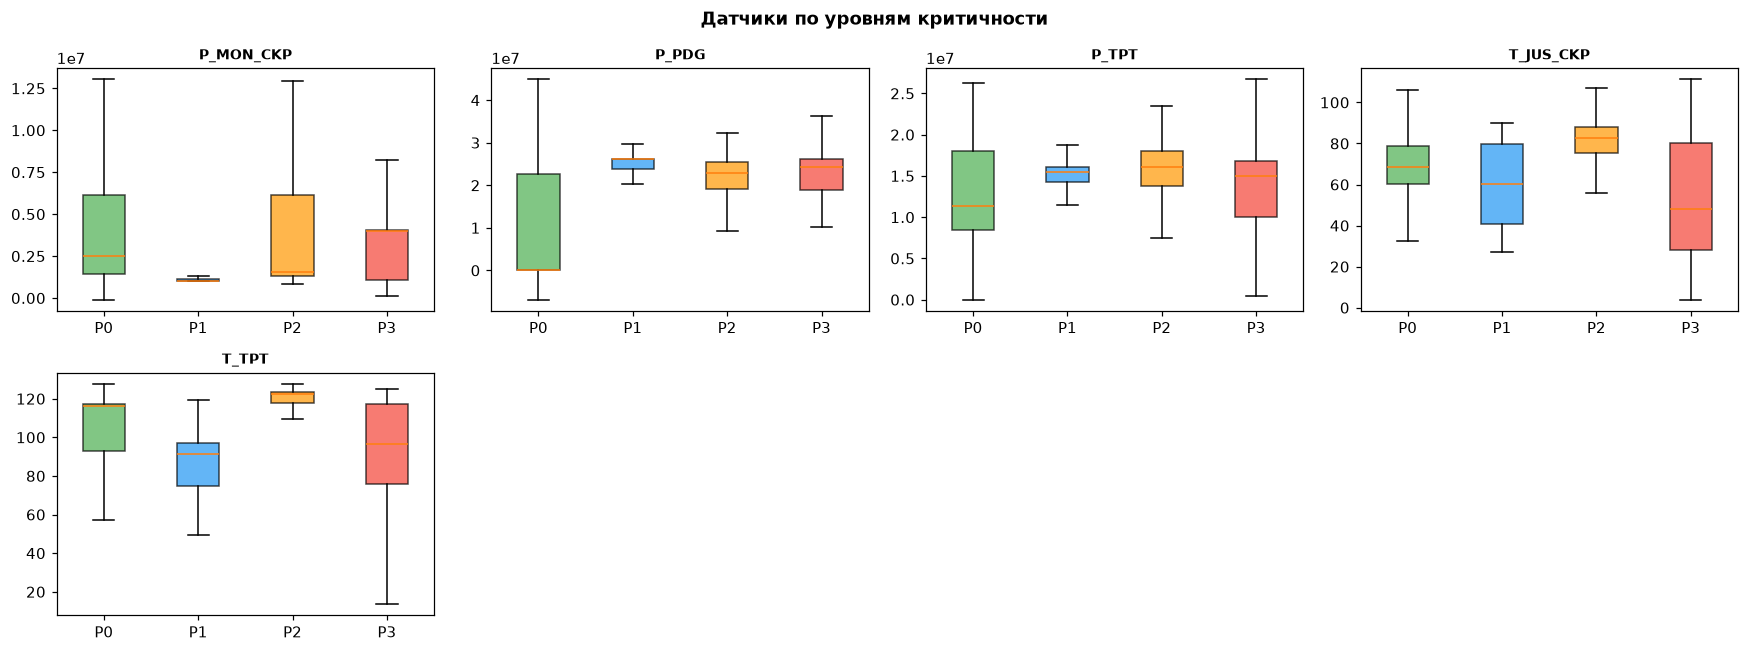

In [16]:
# Распределение датчиков по уровням критичности (выборка до 60k строк для скорости)
samp = df.sample(min(len(df), 60_000), random_state=42)
ncol = 4; nrow = int(np.ceil(len(KEEP) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3 * nrow))
axes = np.atleast_1d(axes).flatten()
for ax, col in zip(axes, KEEP):
    data = [samp.loc[samp["priority"] == p, col].dropna().values for p in range(4)]
    bp = ax.boxplot(data, patch_artist=True, showfliers=False)
    for patch, color in zip(bp["boxes"], COLORS_P):
        patch.set_facecolor(color); patch.set_alpha(0.7)
    ax.set_title(col, fontsize=9, fontweight="bold"); ax.set_xticklabels(["P0", "P1", "P2", "P3"])
for ax in axes[len(KEEP):]:
    ax.axis("off")
fig.suptitle("Датчики по уровням критичности", fontweight="bold")
plt.tight_layout(); plt.show()

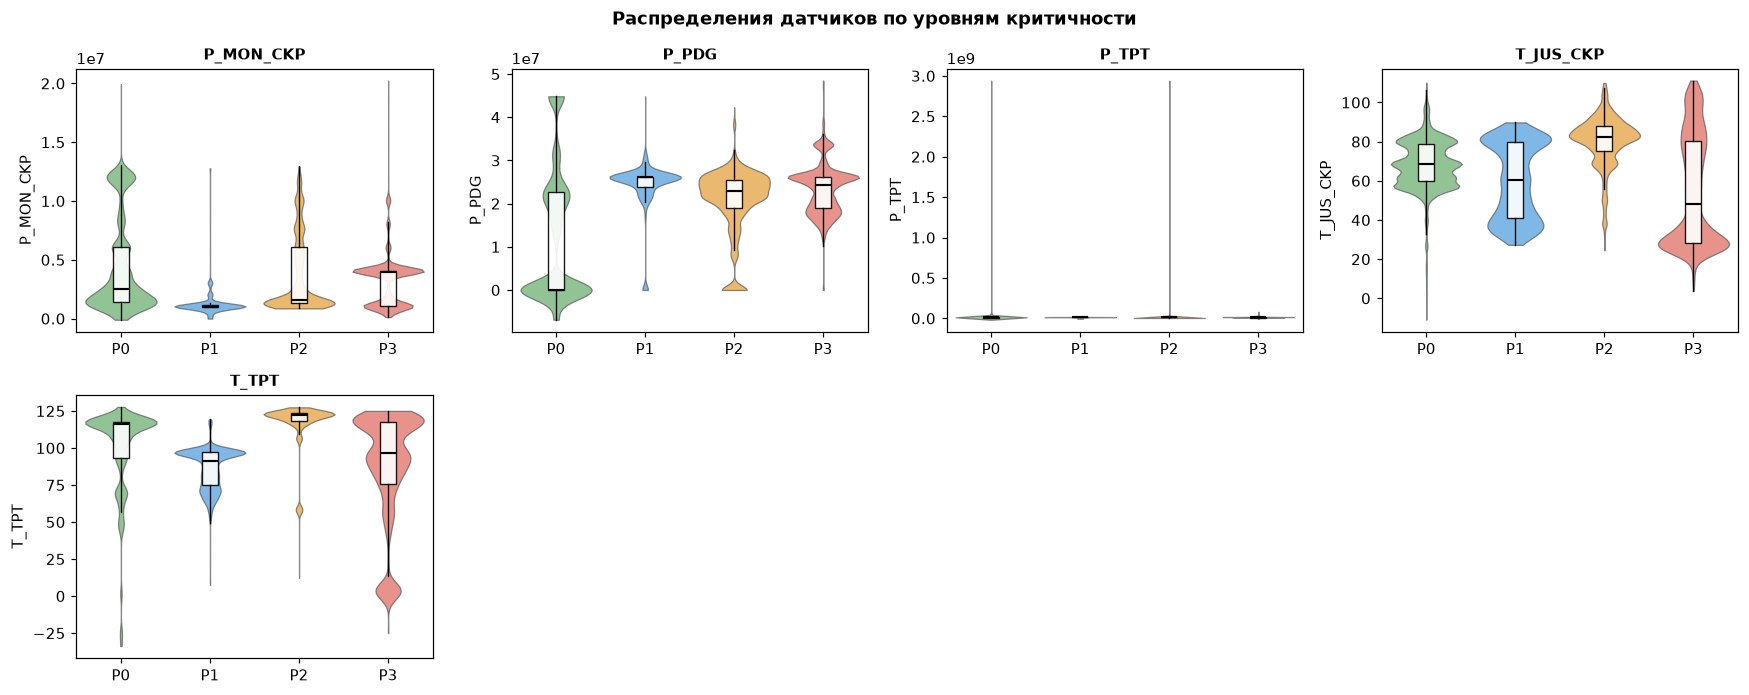

In [17]:
samp = df.sample(min(len(df), 60_000), random_state=42)

# выберите один набор признаков: KEEP или BASE
FEATURES = KEEP  # или BASE

ncol = 4
nrow = int(np.ceil(len(FEATURES) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 3.2 * nrow))
axes = np.atleast_1d(axes).flatten()
for ax, col in zip(axes, FEATURES):
    # 1. Виолин: форма распределения
    sns.violinplot(data=samp, x="priority", y=col, hue="priority", palette=COLORS_P,
                    inner=None, # убираем внутренние квартили, чтобы не конфликтовали с boxplot
                    cut=0, linewidth=0.8, alpha=0.65, legend=False, ax=ax
                    )
    # 2. Boxplot поверх виолина
    data = [
        samp.loc[samp["priority"] == p, col].dropna().values
        for p in range(4)
    ]
    bp = ax.boxplot(data, positions=np.arange(4), widths=0.18, patch_artist=True, showfliers=False, showcaps=False,
        medianprops=dict(color="black", linewidth=1.4), whiskerprops=dict(color="black", linewidth=0.9), boxprops=dict(edgecolor="black", linewidth=0.9),
    )
    for patch in bp["boxes"]:
        patch.set_facecolor("white")
        patch.set_alpha(0.9)

    ax.set_title(col, fontsize=10, fontweight="bold")
    ax.set_xlabel("")
    ax.set_xticks(range(4))
    ax.set_xticklabels(["P0", "P1", "P2", "P3"])

for ax in axes[len(FEATURES):]:
    ax.axis("off")

fig.suptitle("Распределения датчиков по уровням критичности", fontweight="bold")
plt.tight_layout()
plt.show()

Анализ выбросов: правило IQR (1,5·IQR) и правило 3σ

,нижняя граница IQR,верхняя граница IQR,"выбросов IQR, %","выбросов 3σ, %"
датчик,,,,
P_MON_CKP,-4636983.50,10942620.50,6.08,0.04
P_PDG,-4448785.38,44511593.62,4.56,0.00
P_TPT,-1139608.25,28660265.75,1.41,0.03
T_JUS_CKP,17.46,124.06,0.32,0.04
T_TPT,51.01,162.65,5.44,3.45


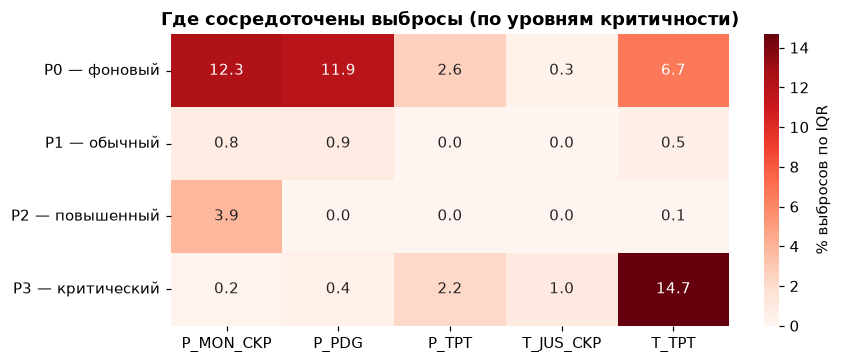

In [18]:
def iqr_bounds(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

rows, out_mask = [], pd.DataFrame(index=df.index)
for c in BASE:
    s = df[c]; lo, hi = iqr_bounds(s.dropna())
    out_mask[c] = (s < lo) | (s > hi)
    z = (s - s.mean()) / s.std()
    rows.append({"датчик": c, "нижняя граница IQR": lo, "верхняя граница IQR": hi,
                 "выбросов IQR, %": out_mask[c].mean() * 100, "выбросов 3σ, %": (z.abs() > 3).mean() * 100})
out_df = pd.DataFrame(rows).set_index("датчик")
display(out_df.round(2))

share = out_mask.groupby(df["priority"]).mean().mul(100)
share.index = [PRIORITY_NAMES[i] for i in share.index]
fig, ax = plt.subplots(figsize=(1.6 + 1.3 * len(BASE), 3.4))
sns.heatmap(share, annot=True, fmt=".1f", cmap="Reds", ax=ax, cbar_kws={"label": "% выбросов по IQR"})
ax.set_title("Где сосредоточены выбросы (по уровням критичности)", fontweight="bold")
plt.tight_layout(); plt.show()

# Вывод для текста: выбросы НЕ удаляются, если они сконцентрированы в аварийных классах — это сам сигнал.
# Удаляются только физически некорректные значения (inf, |x| > 1e12; формула (23) в тексте).

Влияние X на Y: корреляционный анализ (Корреляционный анализ показывает степень монотонной связи. На его основании отбор не производится, так как для нелинейных классификаторов одномерная связь не отражает вклад признака в композицию)

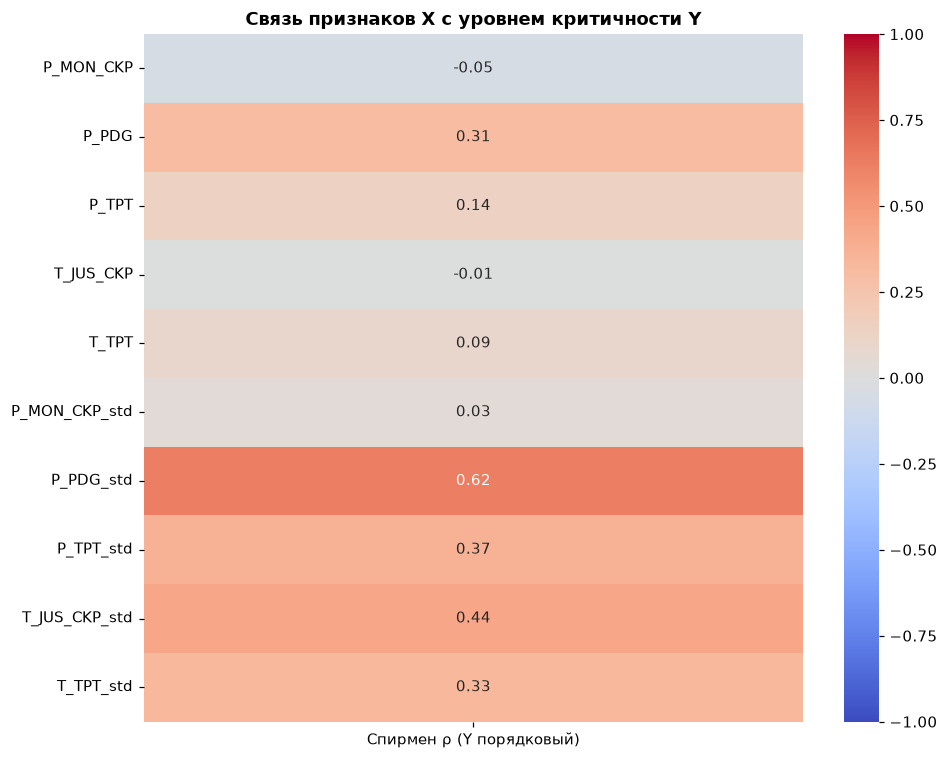

,ρ Спирмена,теснота связи (Чеддок),|ρ| ≥ 0.2
P_MON_CKP,-0.049,связи нет,False
P_PDG,0.311,умеренная,True
P_TPT,0.140,слабая,False
T_JUS_CKP,-0.006,связи нет,False
T_TPT,0.092,связи нет,False
P_MON_CKP_std,0.033,связи нет,False
P_PDG_std,0.621,заметная,True
P_TPT_std,0.373,умеренная,True
T_JUS_CKP_std,0.435,умеренная,True
T_TPT_std,0.334,умеренная,True


Признаки без значимой связи с Y по Спирмену: ['P_MON_CKP', 'P_TPT', 'T_JUS_CKP', 'T_TPT', 'P_MON_CKP_std']

Замечание: Y — порядковая шкала (P0<P1<P2<P3), поэтому основной показатель — ρ Спирмена; «класс против остальных» показывает, какой признак отделяет конкретный уровень.


In [19]:
from scipy import stats as st

CORR_WEAK = 0.2      # граница «значимой связи нет» (|r| < 0,2); меняйте под требование преподавателя

def chaddock(r):
    a = abs(r)
    return ("связи нет" if a < 0.1 else "слабая" if a < 0.3 else "умеренная" if a < 0.5
            else "заметная" if a < 0.7 else "высокая" if a < 0.9 else "весьма высокая")

res = {}
for c in FEATURE_COLS:
    d = df[[c, "priority"]].dropna()
    row = {"Спирмен ρ (Y порядковый)": st.spearmanr(d[c], d["priority"])[0]}
    # for k in range(4):
    #     row[f"{PRIORITY_NAMES[k][:2]} против остальных"] = np.corrcoef(d[c], (d["priority"] == k).astype(float))[0, 1]
    res[c] = row
corr_xy = pd.DataFrame(res).T

fig, ax = plt.subplots(figsize=(9, 0.5 * len(FEATURE_COLS) + 2))
sns.heatmap(corr_xy, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Связь признаков X с уровнем критичности Y", fontweight="bold")
plt.tight_layout(); plt.show()

tab = pd.DataFrame({"ρ Спирмена": corr_xy.iloc[:, 0].round(3),
                    "теснота связи (Чеддок)": corr_xy.iloc[:, 0].map(chaddock),
                    f"|ρ| ≥ {CORR_WEAK}": corr_xy.iloc[:, 0].abs() >= CORR_WEAK})
display(tab)
print("Признаки без значимой связи с Y по Спирмену:", [c for c in FEATURE_COLS if abs(corr_xy.loc[c].iloc[0]) < CORR_WEAK] or "нет")
print("\nЗамечание: Y — порядковая шкала (P0<P1<P2<P3), поэтому основной показатель — ρ Спирмена; "
      "«класс против остальных» показывает, какой признак отделяет конкретный уровень.")

Мультиколлинеарность проверяется как ограничение на входные данные, а не как инструмент отбора: пар с |r| ≥ 0.7 нет, VIF не выше 2.11, отбор по этому критерию не требуется.

Мультиколлинеарность между X

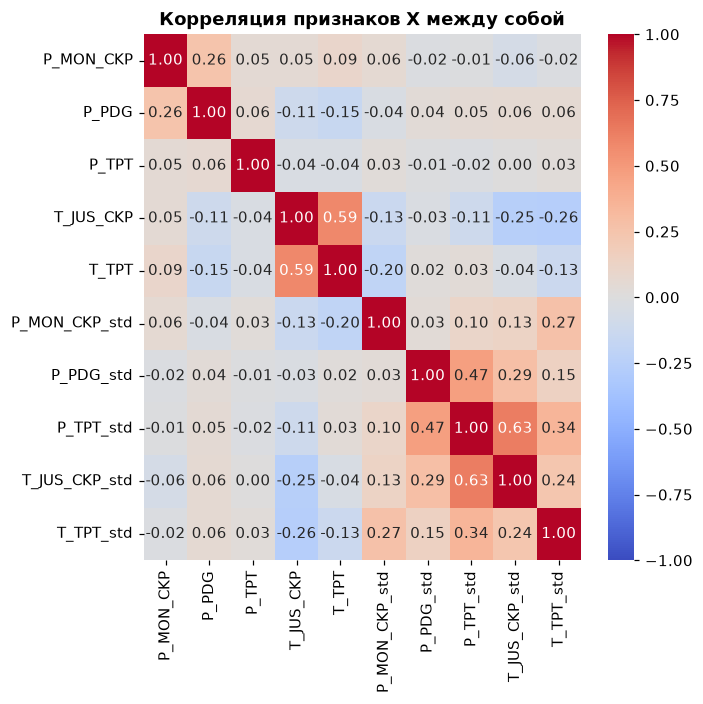

Пары с |r| ≥ 0.7: 0


,VIF,оценка
P_TPT_std,2.11,нет
T_JUS_CKP_std,1.79,нет
T_JUS_CKP,1.73,нет
T_TPT,1.66,нет
P_PDG_std,1.29,нет
T_TPT_std,1.28,нет
P_MON_CKP_std,1.14,нет
P_PDG,1.13,нет
P_MON_CKP,1.12,нет
P_TPT,1.01,нет



После исключения по VIF > 10 осталось 10 из 10: ['P_MON_CKP', 'P_PDG', 'P_TPT', 'T_JUS_CKP', 'T_TPT', 'P_MON_CKP_std', 'P_PDG_std', 'P_TPT_std', 'T_JUS_CKP_std', 'T_TPT_std']


In [21]:
from sklearn.linear_model import LinearRegression

VIF_THRESHOLD = 10          # VIF > 5 — заметная, VIF > 10 — сильная мультиколлинеарность
R_THRESHOLD = 0.7           # |r| >= 0,7

Xc = df[FEATURE_COLS].replace([np.inf, -np.inf], np.nan)
Xc = Xc.where(Xc.abs() < 1e12)
Xc = Xc.fillna(Xc.median())                      # только для анализа, метки не используются

corr = Xc.corr()
fig, ax = plt.subplots(figsize=(1 + 0.55 * len(FEATURE_COLS), 1 + 0.55 * len(FEATURE_COLS)))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Корреляция признаков X между собой", fontweight="bold")
plt.tight_layout(); plt.show()

pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:]
         if abs(corr.loc[a, b]) >= R_THRESHOLD]
print(f"Пары с |r| ≥ {R_THRESHOLD}: {len(pairs)}")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:>16} — {b:<16} r = {r:+.3f}")

def vif_table(frame):
    # VIF_j = 1 / (1 - R_j^2), где R_j^2 — коэффициент детерминации регрессии признака j на остальные
    Z = (frame - frame.mean()) / frame.std().replace(0, np.nan)
    Z = Z.dropna(axis=1)
    out = {}
    for c in Z.columns:
        others = [k for k in Z.columns if k != c]
        r2 = LinearRegression().fit(Z[others], Z[c]).score(Z[others], Z[c]) if others else 0.0
        out[c] = 1 / (1 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF")

vif = vif_table(Xc)
display(pd.DataFrame({"VIF": vif.round(2),
                      "оценка": np.where(vif > 10, "сильная", np.where(vif > 5, "заметная", "нет"))}).sort_values("VIF", ascending=False))

# Последовательное исключение признака с максимальным VIF, пока все VIF <= порога
cols_left = list(Xc.columns)
while len(cols_left) > 1:
    v = vif_table(Xc[cols_left])
    if v.max() <= VIF_THRESHOLD:
        break
    cols_left.remove(v.idxmax())
VIF_COLS = cols_left
print(f"\nПосле исключения по VIF > {VIF_THRESHOLD} осталось {len(VIF_COLS)} из {len(FEATURE_COLS)}: {VIF_COLS}")
# Для деревьев и CatBoost мультиколлинеарность почти не вредит точности (деревья выбирают один из коррелированных
# признаков), но размывает важность между ними и ухудшает устойчивость логистической регрессии.
# Все VIF ниже порога, поэтому отбор по этому критерию не требуется.

## 6. Разделение на обучающую и тестовую выборки — **по скважинам, а не по строкам**

Соседние минутные наблюдения одной скважины почти одинаковы. Если делить случайно по строкам, одна и та же скважина окажется и в обучении, и в тесте, а метрики будут завышены. Поэтому используем `StratifiedGroupKFold`: все данные одной скважины/эпизода попадают целиком либо в train, либо в test, при этом доли классов сохраняются.

In [22]:
X = df[FEATURE_COLS].to_numpy(dtype="float64")

# inf и абсурдно большие значения (выбросы датчиков) -> NaN; дальше их заполнит медиана
bad = np.isinf(X) | (np.abs(X) > 1e12)
print("Некорректных значений по признакам:",
      {c: int(n) for c, n in zip(FEATURE_COLS, bad.sum(axis=0)) if n > 0} or "нет")
X[bad] = np.nan


y = df["priority"].values
groups = df["group" if GROUP_BY == "group" else "file"].values

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(sgkf.split(X, y, groups))

# контроль: ни одна скважина не попала в обе выборки
assert set(groups[train_idx]).isdisjoint(set(groups[test_idx])), "Утечка: скважина и в train, и в test"
print(f"Скважин/эпизодов: train={len(set(groups[train_idx]))}, test={len(set(groups[test_idx]))}")

if len(train_idx) > MAX_TRAIN_ROWS:
    train_idx = np.random.choice(train_idx, MAX_TRAIN_ROWS, replace=False)

X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

# пропуски -> медиана обучающей выборки; масштабирование нужно ТОЛЬКО логистической регрессии
imp = SimpleImputer(strategy="median").fit(X_train)
X_train, X_test = imp.transform(X_train), imp.transform(X_test)
scaler = StandardScaler().fit(X_train)
X_train_sc, X_test_sc = scaler.transform(X_train), scaler.transform(X_test)

dist = pd.DataFrame({"train": np.bincount(y_train, minlength=4),
                     "test":  np.bincount(y_test,  minlength=4)},
                    index=[PRIORITY_NAMES[i] for i in range(4)])
display(dist)
missing = [PRIORITY_NAMES[i] for i in range(4) if dist.iloc[i]["test"] == 0]
if missing:
    print("ВНИМАНИЕ: в тесте нет классов:", missing, "— метрики по ним не определены. "
          "Увеличьте MAX_FILES_PER_CLASS или смените random_state.")

Некорректных значений по признакам: {'P_PDG': 1443}
Скважин/эпизодов: train=408, test=81


,train,test
P0 — фоновый,108104,69538
P1 — обычный,19936,10153
P2 — повышенный,111657,56236
P3 — критический,60303,30328


### 6.0 Баланс классов в выборках

Степень дисбаланса оценивается двумя числами: **коэффициентом дисбаланса** $IR=\dfrac{\max_k N_k}{\min_k N_k}$ и **индексом баланса** $B=\dfrac{H}{\ln K}$, $H=-\sum_k p_k\ln p_k$, $p_k=N_k/N$ ($B=1$ — классы равны). Веса классов считаются по формуле (12) из текста.

In [23]:
def balance_stats(yv):
    n = np.bincount(yv, minlength=4); p = n / n.sum()
    H = -(p[p > 0] * np.log(p[p > 0])).sum()
    return {"N": int(n.sum()), "IR (Nmax/Nmin)": n.max() / n.min(), "индекс баланса B": H / np.log(4),
            **{f"доля P{k}, %": p[k] * 100 for k in range(4)}}

display(pd.DataFrame({"вся выборка": balance_stats(y), "обучающая": balance_stats(y_train),
                      "тестовая": balance_stats(y_test)}).T.round(3))
w_k = len(y_train) / (4 * np.bincount(y_train, minlength=4))
print("Веса классов ω_k = N / (K·N_k), обучающая выборка:", {f"P{k}": round(float(v), 2) for k, v in enumerate(w_k)})

,N,IR (Nmax/Nmin),индекс баланса B,"доля P0, %","доля P1, %","доля P2, %","доля P3, %"
вся выборка,775325.0,5.675,0.891,37.277,6.568,36.443,19.712
обучающая,300000.0,5.601,0.893,36.035,6.645,37.219,20.101
тестовая,166255.0,6.849,0.875,41.826,6.107,33.825,18.242


Веса классов ω_k = N / (K·N_k), обучающая выборка: {'P0': 0.69, 'P1': 3.76, 'P2': 0.67, 'P3': 1.24}


### 6.1 Нормализация признаков и её обоснование

Датчики измеряются в разных единицах (давление — порядка $10^7$ Па, температура — порядка $10^2$ °C, СКО — малые величины), поэтому масштабы признаков отличаются на порядки. Для методов, чувствительных к масштабу (логистическая регрессия, kNN, нейросети), это замедляет сходимость и перекашивает регуляризацию. Деревья, случайный лес и CatBoost работают с порогами «признак ≤ $s$» и инвариантны к монотонным преобразованиям, масштабирование им не нужно.

Сравниваются три способа:

* **десятичное масштабирование:** $x' = x / 10^{j}$, где $j$ — наименьшее целое, при котором $\max|x'| < 1$;
* **минимаксная нормализация:** $x' = \dfrac{x - x_{\min}}{x_{\max} - x_{\min}}$ (значения в $[0,1]$, чувствительна к выбросам);
* **Z-нормализация:** $x' = \dfrac{x - \mu}{\sigma}$ (среднее 0, СКО 1).

Параметры оцениваются только по обучающей выборке.

In [24]:
from sklearn.preprocessing import MinMaxScaler

LABELS = [0, 1, 2, 3]

class DecimalScaler:
    """Десятичное масштабирование: x / 10^j, j = floor(log10(max|x|)) + 1 (оценивается по обучающей выборке)."""
    def fit(self, X):
        m = np.nanmax(np.abs(X), axis=0)
        self.j_ = np.floor(np.log10(np.where(m == 0, 1, m))) + 1
        return self
    def transform(self, X):
        return X / 10.0 ** self.j_

print("Масштаб признаков до нормализации (обучающая выборка):")
display(pd.DataFrame({"min": X_train.min(axis=0), "max": X_train.max(axis=0),
                      "std": X_train.std(axis=0)}, index=FEATURE_COLS).map(lambda v: f"{v:.3g}"))

scalers = {"без масштабирования": None, "десятичное": DecimalScaler(),
           "минимаксная": MinMaxScaler(), "Z-нормализация": StandardScaler()}
rows = {}
for nm, sc in scalers.items():
    if sc is None:
        A_, B_ = X_train, X_test
    else:
        sc.fit(X_train); A_, B_ = sc.transform(X_train), sc.transform(X_test)
    lr_ = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42).fit(A_, y_train)
    p_ = lr_.predict(B_)
    rows[nm] = {"Accuracy": accuracy_score(y_test, p_),
                "F1-macro": f1_score(y_test, p_, labels=LABELS, average="macro", zero_division=0),
                "F1 (P3)": f1_score(y_test, p_, labels=LABELS, average=None, zero_division=0)[3],
                "итераций до сходимости": int(np.max(lr_.n_iter_))}
print("\nИллюстрация необходимости нормализации на модели, чувствительной к масштабу (LR)." \
"В основном сравнении эта модель не участвует — все три рабочие модели (DT, RF, CatBoost) инвариантны к масштабу. (max_iter = 2000):")
norm_tbl = pd.DataFrame(rows).T
norm_tbl["итераций до сходимости"] = norm_tbl["итераций до сходимости"].astype(int)
norm_tbl["сошлась"] = np.where(norm_tbl["итераций до сходимости"] < 2000, "да", "нет")
display(norm_tbl.round(3))

# Деревья инвариантны к масштабированию: одинаковое качество на исходных и минимакс-признаках
mm = MinMaxScaler().fit(X_train)
t_raw = DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42).fit(X_train, y_train)
t_mm  = DecisionTreeClassifier(max_depth=12, class_weight="balanced", random_state=42).fit(mm.transform(X_train), y_train)
print(f"\nДерево решений: accuracy на исходных признаках = {accuracy_score(y_test, t_raw.predict(X_test)):.4f}, "
      f"на минимакс-признаках = {accuracy_score(y_test, t_mm.predict(mm.transform(X_test))):.4f}")

Масштаб признаков до нормализации (обучающая выборка):


,min,max,std
P_MON_CKP,-9.63e+04,2.02e+07,3.38e+06
P_PDG,-1.19e+08,4.85e+07,1.02e+07
P_TPT,-1.71e+07,2.94e+09,5.61e+07
T_JUS_CKP,-11.2,111,19.3
T_TPT,-33.8,128,30
P_MON_CKP_std,0,6.15e+06,1.12e+05
P_PDG_std,0,4.55e+07,4.58e+05
P_TPT_std,0,5.67e+06,2.17e+05
T_JUS_CKP_std,0,25.7,1.15
T_TPT_std,0,21.4,0.366



Иллюстрация необходимости нормализации на модели, чувствительной к масштабу (LR).В основном сравнении эта модель не участвует — все три рабочие модели (DT, RF, CatBoost) инвариантны к масштабу. (max_iter = 2000):


,Accuracy,F1-macro,F1 (P3),итераций до сходимости,сошлась
без масштабирования,0.446,0.457,0.634,2000,нет
десятичное,0.764,0.733,0.768,206,да
минимаксная,0.774,0.745,0.792,409,да
Z-нормализация,0.760,0.738,0.817,69,да



Дерево решений: accuracy на исходных признаках = 0.8907, на минимакс-признаках = 0.7361


## 7. Обучение и сравнение моделей

Главные метрики: **recall и F1 класса P3** — аварии нельзя пропускать, и **доля пропущенных аварий** (P3, определённых как P0/P1).

In [25]:
models = {
    "Дерево решений": DecisionTreeClassifier(
        max_depth=12, class_weight="balanced", random_state=42),
    "Случайный лес": RandomForestClassifier(
        n_estimators=100, class_weight="balanced",
        min_samples_leaf=3, random_state=42, n_jobs=-1),
    "CatBoost": CatBoostClassifier(
        iterations=300,
        depth=6,
        learning_rate=0.1,
        loss_function="MultiClass",
        auto_class_weights="Balanced",     # аналог class_weight='balanced'
        random_seed=42,
        verbose=0, # 0 - не засорять вывод
        
        ),                        
}

LABELS = [0, 1, 2, 3]
results = {}
for name, model in models.items():
    t0 = time.time()

    # деревья, лес и CatBoost работают с исходными (немасштабированными) признаками
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # if y_pred.ndim > 1:                # CatBoost иногда возвращает (n,1)
    #     y_pred = y_pred.ravel()
    y_pred = np.asarray(y_pred).ravel().astype(int)

    f1_cls  = f1_score(y_test, y_pred, labels=LABELS, average=None, zero_division=0)
    rec_cls = recall_score(y_test, y_pred, labels=LABELS, average=None, zero_division=0)
    p3 = y_test == 3
    missed = np.isin(y_pred[p3], [0, 1]).mean() if p3.any() else np.nan #missed = (y_pred[p3] != 3).mean()

    results[name] = dict(model=model, y_pred=y_pred, f1_cls=f1_cls, rec_cls=rec_cls,
                         accuracy=accuracy_score(y_test, y_pred),
                         f1_macro=f1_score(y_test, y_pred, labels=LABELS,
                                           average="macro", zero_division=0),
                         f1_p3=f1_cls[3], recall_p3=rec_cls[3], missed_p3=missed)
    print(f"{name:<16} обучена за {time.time()-t0:.0f} c")

table = pd.DataFrame({n: {"Accuracy": r["accuracy"], "F1-macro": r["f1_macro"],
                          "F1 (P3)": r["f1_p3"], "Recall (P3)": r["recall_p3"],
                          "Пропущено аварий (P3→P0/P1)": r["missed_p3"]}
                      for n, r in results.items()}).T
display(table.round(3))



Дерево решений   обучена за 4 c
Случайный лес    обучена за 26 c
CatBoost         обучена за 24 c


,Accuracy,F1-macro,F1 (P3),Recall (P3),Пропущено аварий (P3→P0/P1)
Дерево решений,0.891,0.912,0.962,0.933,0.007
Случайный лес,0.890,0.918,0.966,0.938,0.011
CatBoost,0.894,0.920,0.951,0.978,0.000


In [26]:
from sklearn.base import clone
from sklearn.metrics import precision_score

def evaluate_without(feature_to_drop, model_name="CatBoost"):
    cols = [c for c in FEATURE_COLS if c != feature_to_drop]
    keep_idx = [FEATURE_COLS.index(c) for c in cols]

    m = clone(models[model_name])
    m.fit(X_train[:, keep_idx], y_train)

    pred = np.asarray(m.predict(X_test[:, keep_idx])).ravel().astype(int)

    f1_cls = f1_score(
        y_test, pred, labels=LABELS, average=None, zero_division=0
    )
    rec_cls = recall_score(
        y_test, pred, labels=LABELS, average=None, zero_division=0
    )

    return {
        "f1_macro": f1_score(
            y_test, pred, labels=LABELS, average="macro", zero_division=0
        ),
        "f1_p3": f1_cls[3],
        "recall_p3": rec_cls[3],
        "precision_p3": precision_score(
            y_test, pred, labels=LABELS, average=None, zero_division=0
        )[3],
    }

print(evaluate_without("T_JUS_CKP"))

{'f1_macro': 0.9067189605098258, 'f1_p3': np.float64(0.9181950878974424), 'recall_p3': np.float64(0.9541018201002374), 'precision_p3': np.float64(0.8848929663608562)}


In [27]:
from sklearn.metrics import confusion_matrix, classification_report

for name, r in results.items():
    print("\n" + name)
    print(confusion_matrix(y_test, r["y_pred"], labels=LABELS))
    print(classification_report(
        y_test, r["y_pred"], labels=LABELS,
        target_names=["P0", "P1", "P2", "P3"],
        zero_division=0
    ))


Дерево решений
[[68821     0   717     0]
 [  480  9513     0   160]
 [14750    13 41446    27]
 [  112   106  1812 28298]]
              precision    recall  f1-score   support

          P0       0.82      0.99      0.90     69538
          P1       0.99      0.94      0.96     10153
          P2       0.94      0.74      0.83     56236
          P3       0.99      0.93      0.96     30328

    accuracy                           0.89    166255
   macro avg       0.94      0.90      0.91    166255
weighted avg       0.90      0.89      0.89    166255


Случайный лес
[[67673     0  1839    26]
 [  192  9898     0    63]
 [14282     0 41953     1]
 [  326     0  1556 28446]]
              precision    recall  f1-score   support

          P0       0.82      0.97      0.89     69538
          P1       1.00      0.97      0.99     10153
          P2       0.93      0.75      0.83     56236
          P3       1.00      0.94      0.97     30328

    accuracy                           0.89 

In [28]:
feature = "T_JUS_CKP"
model_name = "CatBoost"

base = results[model_name]
ablated = evaluate_without(feature, model_name)

print({
    "F1_macro": [base["f1_macro"], ablated["f1_macro"]],
    "F1_P3": [base["f1_p3"], ablated["f1_p3"]],
    "Recall_P3": [base["recall_p3"], ablated["recall_p3"]],
    "Precision_P3": [
        precision_score(
            y_test, base["y_pred"], labels=LABELS, average=None, zero_division=0
        )[3],
        ablated["precision_p3"],
    ],
})

{'F1_macro': [0.9197350740558762, 0.9067189605098258], 'F1_P3': [np.float64(0.9506178775784969), np.float64(0.9181950878974424)], 'Recall_P3': [np.float64(0.9778092851490372), np.float64(0.9541018201002374)], 'Precision_P3': [np.float64(0.9248978573433553), np.float64(0.8848929663608562)]}


## 8. Детальный анализ

In [29]:
# Основная модель — CatBoost
y_pred_best = results["CatBoost"]["y_pred"]
print(classification_report(y_test, y_pred_best, labels=LABELS,
                            target_names=CLASS_NAMES, zero_division=0))

                  precision    recall  f1-score   support

    P0 — фоновый       0.83      0.96      0.89     69538
    P1 — обычный       1.00      0.98      0.99     10153
 P2 — повышенный       0.97      0.75      0.85     56236
P3 — критический       0.92      0.98      0.95     30328

        accuracy                           0.89    166255
       macro avg       0.93      0.92      0.92    166255
    weighted avg       0.90      0.89      0.89    166255



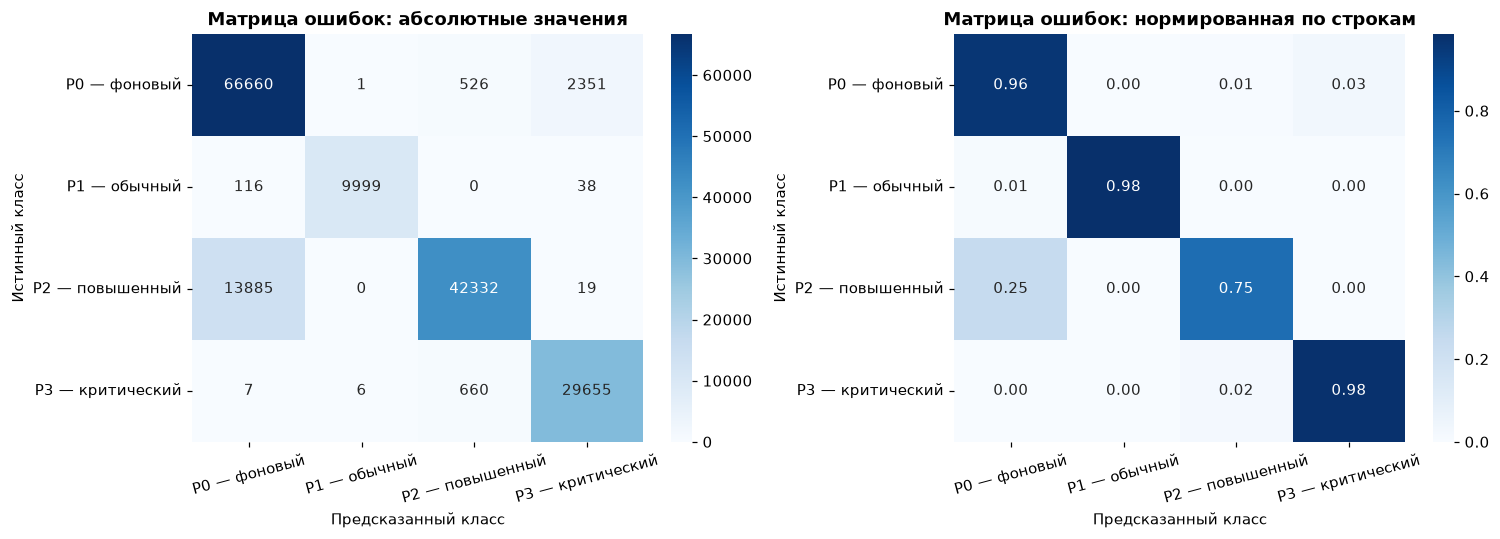

In [30]:
cm = confusion_matrix(y_test, y_pred_best, labels=LABELS)
cm_norm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, data, fmt, title in [(axes[0], cm, "d", "абсолютные значения"),
                             (axes[1], cm_norm, ".2f", "нормированная по строкам")]:
    sns.heatmap(data, annot=True, fmt=fmt, cmap="Blues", ax=ax,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"Матрица ошибок: {title}", fontweight="bold")
    ax.set_ylabel("Истинный класс"); ax.set_xlabel("Предсказанный класс")
    ax.tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

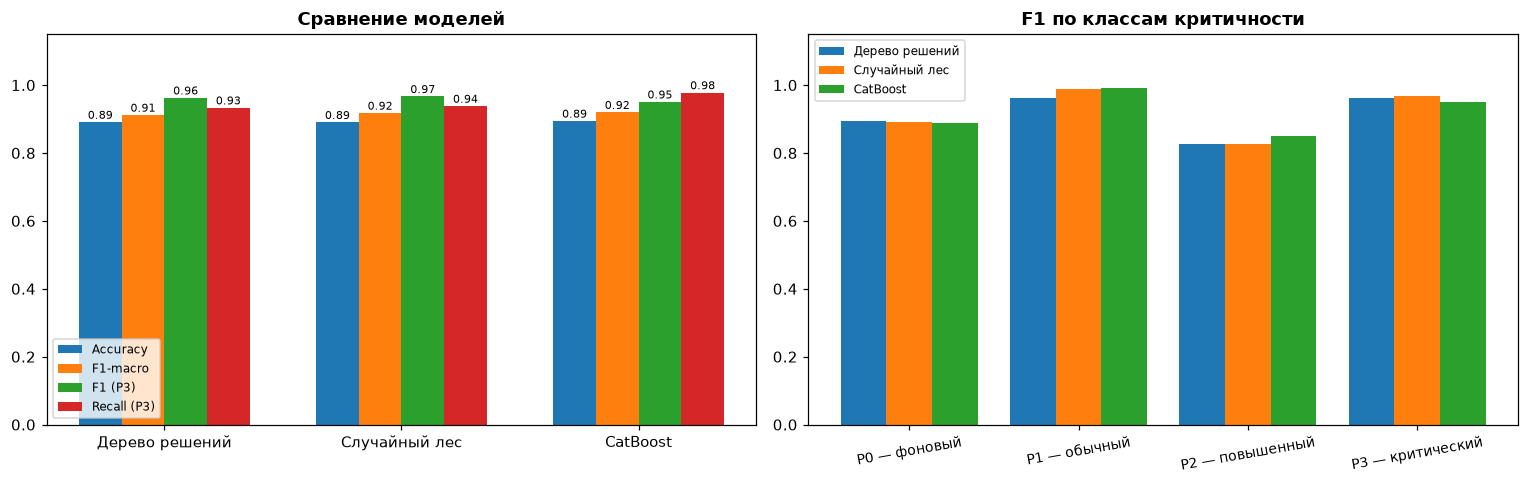

In [31]:
names = list(results.keys())
x = np.arange(len(names)); w = 0.18    # чуть уже при 4 моделях
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for i, (lab, key) in enumerate([("Accuracy", "accuracy"), ("F1-macro", "f1_macro"),
                                ("F1 (P3)", "f1_p3"), ("Recall (P3)", "recall_p3")]):
    vals = [results[n][key] for n in names]
    bars = axes[0].bar(x + (i - 1.5) * w, vals, w, label=lab)
    for b in bars:
        axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.01,
                     f"{b.get_height():.2f}", ha="center", fontsize=7)
axes[0].set_xticks(x); axes[0].set_xticklabels(names); axes[0].set_ylim(0, 1.15)
axes[0].set_title("Сравнение моделей", fontweight="bold"); axes[0].legend(fontsize=8)

x2 = np.arange(4); w2 = 0.27
for i, n in enumerate(names):
    axes[1].bar(x2 + (i - 1) * w2, results[n]["f1_cls"], w2, label=n)
axes[1].set_xticks(x2); axes[1].set_xticklabels(CLASS_NAMES, rotation=10, fontsize=9)
axes[1].set_ylim(0, 1.15); axes[1].set_title("F1 по классам критичности", fontweight="bold")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 8.1 Валидация: кросс-валидация и метод Монте-Карло (по скважинам)

Одно разбиение даёт одну оценку, которая зависит от того, какие скважины попали в тест. Поэтому качество оценивается ещё двумя способами:

* **кросс-валидация** — 5 блоков: каждая скважина один раз оказывается в тесте;
* **метод Монте-Карло** — многократное случайное разбиение 80/20 (каждый раз новое), по которому видно разброс метрик.

Разбиение везде идёт **по скважинам** и стратифицировано по классам; предобработка (медиана, масштаб) оценивается заново на каждой обучающей части.

Кросс-валидация готова за 847 c
Монте-Карло готов за 1660 c

кросс-валидация (среднее ± СКО по разбиениям):


,Accuracy,F1-macro,F1 (P3),Recall (P3),Пропущено аварий
модель,,,,,
Дерево решений,0.844 ± 0.063,0.841 ± 0.077,0.919 ± 0.074,0.904 ± 0.119,0.073 ± 0.13
Случайный лес,0.853 ± 0.099,0.869 ± 0.114,0.93 ± 0.074,0.909 ± 0.13,0.068 ± 0.13
CatBoost,0.863 ± 0.104,0.89 ± 0.089,0.943 ± 0.048,0.938 ± 0.097,0.054 ± 0.101



Монте-Карло (среднее ± СКО по разбиениям):


,Accuracy,F1-macro,F1 (P3),Recall (P3),Пропущено аварий
модель,,,,,
Дерево решений,0.856 ± 0.028,0.885 ± 0.025,0.979 ± 0.006,0.966 ± 0.013,0.007 ± 0.001
Случайный лес,0.894 ± 0.005,0.921 ± 0.005,0.978 ± 0.007,0.97 ± 0.013,0.009 ± 0.002
CatBoost,0.895 ± 0.007,0.92 ± 0.008,0.957 ± 0.016,0.991 ± 0.01,0.001 ± 0.0


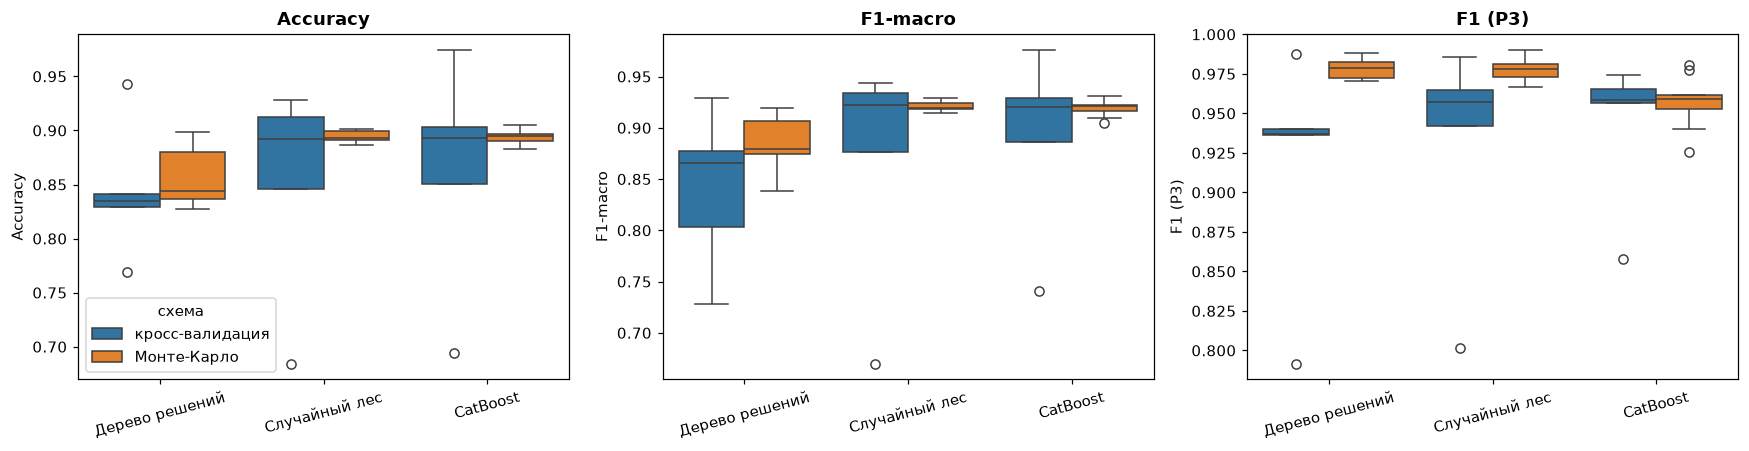

In [ ]:
CV_FOLDS = 5
MC_REPEATS = 10          # число случайных разбиений Монте-Карло (увеличьте до 30 для финального прогона)
METRICS = ["Accuracy", "F1-macro", "F1 (P3)", "Recall (P3)", "Пропущено аварий"]

def fit_eval(name, base_model, Xtr, ytr, Xte, yte):
    imp_ = SimpleImputer(strategy="median").fit(Xtr)
    A_, B_ = imp_.transform(Xtr), imp_.transform(Xte)
    
    m = copy.deepcopy(base_model); m.fit(A_, ytr)
    pred = np.asarray(m.predict(B_)).ravel().astype(int)
    f1c = f1_score(yte, pred, labels=LABELS, average=None, zero_division=0)
    p3 = yte == 3
    return {"Accuracy": accuracy_score(yte, pred),
            "F1-macro": f1_score(yte, pred, labels=LABELS, average="macro", zero_division=0),
            "F1 (P3)": f1c[3],
            "Recall (P3)": recall_score(yte, pred, labels=LABELS, average=None, zero_division=0)[3],
            "Пропущено аварий": np.isin(pred[p3], [0, 1]).mean() if p3.any() else np.nan}

val_rows = []
t0 = time.time()
for fold, (tr, te) in enumerate(StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=7).split(X, y, groups), 1):
    for name, m in models.items():
        r = fit_eval(name, m, X[tr], y[tr], X[te], y[te]); r.update({"модель": name, "схема": "кросс-валидация"}); val_rows.append(r)
print(f"Кросс-валидация готова за {time.time()-t0:.0f} c")

t0 = time.time()
for i in range(MC_REPEATS):
    tr, te = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=100 + i).split(X, y, groups))
    for name, m in models.items():
        r = fit_eval(name, m, X[tr], y[tr], X[te], y[te]); r.update({"модель": name, "схема": "Монте-Карло"}); val_rows.append(r)
print(f"Монте-Карло готов за {time.time()-t0:.0f} c")

val = pd.DataFrame(val_rows)
for scheme in ("кросс-валидация", "Монте-Карло"):
    s = val[val["схема"] == scheme].groupby("модель")[METRICS].agg(["mean", "std"])
    out = pd.DataFrame({m: s[m]["mean"].round(3).astype(str) + " ± " + s[m]["std"].round(3).astype(str) for m in METRICS})
    print(f"\n{scheme} (среднее ± СКО по разбиениям):")
    display(out.loc[list(models.keys())])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, metric in zip(axes, ["Accuracy", "F1-macro", "F1 (P3)"]):
    sns.boxplot(data=val, x="модель", y=metric, hue="схема", order=list(models.keys()), ax=ax)
    ax.set_title(metric, fontweight="bold"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
    if ax is not axes[0]: ax.get_legend().remove()
plt.tight_layout(); plt.show()

### 8.2 Аналоги регрессионных критериев для классификации

Коэффициент детерминации $R^2$, критерий Акаике и среднеквадратическая ошибка аппроксимации определены для регрессии. Для классификатора, который выдаёт вероятности $p_{ik}$ классов, используются их прямые аналоги:

* **СКО аппроксимации вероятностей** — многоклассовая оценка Брайера: $BS=\dfrac1N\sum_i\sum_k\left(p_{ik}-\mathbb{1}[y_i=k]\right)^2$;
* **псевдо-$R^2$ Макфаддена:** $R^2_{McF}=1-\dfrac{\ln L_{\text{модели}}}{\ln L_{\text{нулевой}}}$, где нулевая модель всегда выдаёт доли классов обучающей выборки (значения 0,2–0,4 считаются очень хорошим согласием);
* **порядковый $R^2$ и СКО:** так как $Y$ упорядочен (P0<P1<P2<P3), ожидаемый уровень $\hat y_i=\sum_k k\,p_{ik}$, $R^2_{ord}=1-\dfrac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$, $RMSE=\sqrt{\frac1N\sum(y_i-\hat y_i)^2}$;
* **AIC и BIC** считаются только для модели с правдоподобием — логистической регрессии: $AIC=2k-2\ln L$, $BIC=k\ln n-2\ln L$, $k=(K-1)(d+1)$. Для леса и CatBoost они не определены, там сравнение идёт по log-loss и валидации.

AIC и BIC определены только для параметрических моделей с явным правдоподобием (LR, CatBoost с MultiClass loss — правдоподобие есть, но регуляризация через веса классов ломает интерпретацию; для RF правдоподобия нет). Поэтому информационные критерии в работе не используются; сравнение по вероятностям ведётся через log-loss, Brier и псевдо-R² Макфаддена.

In [32]:
from sklearn.metrics import log_loss, roc_auc_score

def get_proba(name, m):
    return np.asarray(m.predict_proba(X_test))

prior = np.bincount(y_train, minlength=4) / len(y_train)
ll_null = log_loss(y_test, np.tile(prior, (len(y_test), 1)), labels=LABELS)
Y1 = np.eye(4)[y_test]
rows = {}
for name, r in results.items():
    P = np.clip(get_proba(name, r["model"]), 1e-15, 1); P = P / P.sum(axis=1, keepdims=True)
    ll = log_loss(y_test, P, labels=LABELS)
    ev = P @ np.arange(4)
    pred = P.argmax(axis=1)
    rows[name] = {
        "Brier (СКО вероятностей)": ((P - Y1) ** 2).sum(axis=1).mean(),
        "log-loss": ll,
        "псевдо-R² Макфаддена": 1 - ll / ll_null,
        "порядковый R²": 1 - ((y_test - ev) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum(),
        "RMSE (ожид. уровень)": np.sqrt(np.mean((ev - y_test) ** 2)),
        "MAE (метки)": np.mean(np.abs(pred - y_test)),
        "ROC-AUC (OvR, macro)": roc_auc_score(y_test, P, multi_class="ovr", average="macro", labels=LABELS),
    }
approx = pd.DataFrame(rows).T
print(f"log-loss нулевой модели (доли классов): {ll_null:.3f}")
display(approx.round(3))

log-loss нулевой модели (доли классов): 1.219


,Brier (СКО вероятностей),log-loss,псевдо-R² Макфаддена,порядковый R²,RMSE (ожид. уровень),MAE (метки),"ROC-AUC (OvR, macro)"
Дерево решений,0.209,1.318,-0.081,0.732,0.613,0.205,0.937
Случайный лес,0.204,0.404,0.669,0.693,0.656,0.212,0.959
CatBoost,0.200,0.608,0.501,0.689,0.661,0.221,0.924


### 8.3 Качество по источникам данных (проверка связи класса и источника)

Уровень критичности в выборке сильно связан с источником (смоделированные экземпляры преобладают в P2 и P3, реальные — в P0). Если модель опирается на отличия «симуляция / реальная скважина», качество на реальных скважинах будет заметно ниже. Проверяем на тестовой выборке отдельно по источникам.

In [33]:
src_all = df["source"].values
src_test = src_all[test_idx]
print("Состав тестовой выборки по источникам и уровням:")
display(pd.crosstab(pd.Series(src_test, name="источник"), pd.Series(y_test, name="уровень").map(lambda k: f"P{k}")))

rows = []
for name in ("Случайный лес", "CatBoost"):
    yp = results[name]["y_pred"]
    for s in np.unique(src_test):
        m = src_test == s
        present = [k for k in LABELS if (y_test[m] == k).any()]
        p3 = m & (y_test == 3)
        rows.append({"модель": name, "источник": s, "наблюдений": int(m.sum()),
                     "классы в тесте": ",".join(f"P{k}" for k in present),
                     "Accuracy": accuracy_score(y_test[m], yp[m]),
                     "F1-macro (по присутствующим)": f1_score(y_test[m], yp[m], labels=present, average="macro", zero_division=0),
                     "Recall P3": (yp[p3] == 3).mean() if p3.any() else np.nan})
display(pd.DataFrame(rows).round(3))
print("Если метрики на WELL заметно ниже, чем на SIMULATED, результат нужно описывать как зависимый от источника.\n"
      "Для полной проверки повторите весь ноутбук с SOURCES = ('WELL',) и MAX_FILES_PER_CLASS = None.")

Состав тестовой выборки по источникам и уровням:


уровень,P0,P1,P2,P3
источник,,,,
SIMULATED,7967,10101,42534,30323
WELL,61571,52,13702,5


,модель,источник,наблюдений,классы в тесте,Accuracy,F1-macro (по присутствующим),Recall P3
0,Случайный лес,SIMULATED,90925,"P0,P1,P2,P3",0.969,0.966,0.938
1,Случайный лес,WELL,75330,"P0,P1,P2,P3",0.794,0.294,1.000
2,CatBoost,SIMULATED,90925,"P0,P1,P2,P3",0.983,0.979,0.978
3,CatBoost,WELL,75330,"P0,P1,P2,P3",0.786,0.221,1.000


Если метрики на WELL заметно ниже, чем на SIMULATED, результат нужно описывать как зависимый от источника.
Для полной проверки повторите весь ноутбук с SOURCES = ('WELL',) и MAX_FILES_PER_CLASS = None.


### 8.4 Наборы признаков: средние, средние + СКО, + разности (лаги)

Все VIF ниже порога, поэтому сравнение «до и после исключения по VIF» ничего не меняло. Вместо него на том же разбиении сравниваются три набора признаков: только средние за минуту, средние и скользящее СКО, средние, СКО и разности $x(t)-x(t-k)$ (тренд за $k$ минут). Если разности не нужны (`LAGS = ()`), третий набор не строится.

In [34]:
def make_xy(cols):
    A = df[cols].to_numpy(dtype="float64")
    A[np.isinf(A) | (np.abs(A) > 1e12)] = np.nan
    im = SimpleImputer(strategy="median").fit(A[train_idx])
    return im.transform(A[train_idx]), im.transform(A[test_idx])

sets = {f"средние ({len(KEEP)})": KEEP,
        f"средние + СКО ({len(BASE_FEATURES)})": BASE_FEATURES}
if LAG_COLS:
    sets[f"средние + СКО + разности ({len(BASE_FEATURES) + len(LAG_COLS)})"] = BASE_FEATURES + LAG_COLS

rows = {}
for set_name, cols in sets.items():
    A_tr, A_te = make_xy(cols)
    for name in ("Случайный лес", "CatBoost"):
        m = copy.deepcopy(models[name]); m.fit(A_tr, y_train)
        p_ = np.asarray(m.predict(A_te)).ravel().astype(int); p3 = y_test == 3
        rc = recall_score(y_test, p_, labels=LABELS, average=None, zero_division=0)
        rows[f"{name} | {set_name}"] = {
            "Accuracy": accuracy_score(y_test, p_),
            "F1-macro": f1_score(y_test, p_, labels=LABELS, average="macro", zero_division=0),
            "Recall P1": rc[1], "Recall P2": rc[2], "Recall P3": rc[3],
            "Пропущено аварий": np.isin(p_[p3], [0, 1]).mean()}
display(pd.DataFrame(rows).T.round(3))
print("Набор признаков принимается только если он улучшает F1-macro заметно больше разброса метода Монте-Карло "
      "(раздел 8.1) и не ухудшает долю пропущенных аварий.")

,Accuracy,F1-macro,Recall P1,Recall P2,Recall P3,Пропущено аварий
Случайный лес | средние (5),0.865,0.894,0.949,0.643,0.939,0.006
CatBoost | средние (5),0.899,0.920,0.952,0.756,0.957,0.006
Случайный лес | средние + СКО (10),0.890,0.918,0.975,0.746,0.938,0.011
CatBoost | средние + СКО (10),0.894,0.920,0.985,0.753,0.978,0.000
Случайный лес | средние + СКО + разности (20),0.908,0.932,0.985,0.757,0.965,0.007
CatBoost | средние + СКО + разности (20),0.909,0.933,0.986,0.756,0.987,0.001


Набор признаков принимается только если он улучшает F1-macro заметно больше разброса метода Монте-Карло (раздел 8.1) и не ухудшает долю пропущенных аварий.


### 8.5 CatBoost: кривая обучения, валидация по скважинам и early stopping

Лог обучения CatBoost (`learn_error.tsv`) показывает только ошибку на обучающих данных: к 300-й итерации она падает почти до нуля. Это не доказывает качества на новых скважинах. Чтобы увидеть переобучение, часть **обучающих** скважин выделяется в валидационную выборку (тест не используется), и обе кривые строятся вместе; обучение останавливается, когда ошибка на валидации перестаёт уменьшаться (early stopping).

Обучение: 240,808 строк, валидация: 59,192 строк (скважины не пересекаются)


,лучшая итерация,ошибка на обучении,ошибка на валидации,Accuracy (тест),F1-macro (тест),Пропущено аварий (тест)
depth,,,,,,
4,274.0,0.1834,0.6298,0.8839,0.8957,0.0271
6,265.0,0.1072,0.6442,0.8974,0.9182,0.0109
8,219.0,0.0830,0.6158,0.8993,0.9203,0.0061


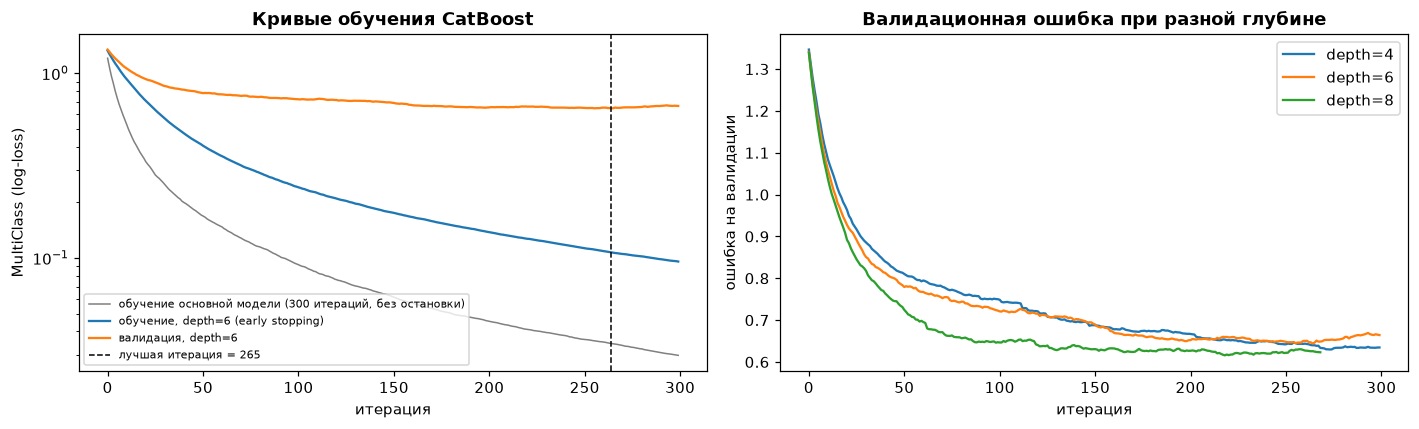

Разрыв между ошибкой на обучении и на валидации — мера переобучения под обучающие скважины.


In [35]:
from catboost import CatBoostClassifier

g_tr = groups[train_idx]
a_idx, v_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=11).split(X_train, y_train, g_tr))

assert set(g_tr[a_idx]).isdisjoint(set(g_tr[v_idx]))
print(f"Обучение: {len(a_idx):,} строк, валидация: {len(v_idx):,} строк (скважины не пересекаются)")

cb_tuned, curves = {}, {}
for depth in (4, 6, 8):
    cb = CatBoostClassifier(iterations=300, depth=depth, l2_leaf_reg=3, learning_rate=0.03, loss_function="MultiClass", eval_metric="MultiClass",
                            auto_class_weights="Balanced", random_seed=42, verbose=0, random_strength=1, bagging_temperature=1,
                            early_stopping_rounds=50)
    cb.fit(
        X_train[a_idx],
        y_train[a_idx],
        eval_set=(X_train[v_idx], y_train[v_idx]),
        use_best_model=True
    )

    ev = cb.get_evals_result()
    curves[depth] = (ev["learn"]["MultiClass"], ev["validation"]["MultiClass"], cb.get_best_iteration())
    p_ = np.asarray(cb.predict(X_test)).ravel().astype(int)
    p3 = y_test == 3
    cb_tuned[depth] = {"лучшая итерация": cb.get_best_iteration() + 1,
                       "ошибка на обучении": curves[depth][0][cb.get_best_iteration()],
                       "ошибка на валидации": curves[depth][1][cb.get_best_iteration()],
                       "Accuracy (тест)": accuracy_score(y_test, p_),
                       "F1-macro (тест)": f1_score(y_test, p_, labels=LABELS, average="macro", zero_division=0),
                       "Пропущено аварий (тест)": np.isin(p_[p3], [0, 1]).mean()}
display(pd.DataFrame(cb_tuned).T.round(4).rename_axis("depth"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
try:
    main_learn = results["CatBoost"]["model"].get_evals_result()["learn"]["MultiClass"]
    axes[0].plot(main_learn, color="gray", lw=1, label="обучение основной модели (300 итераций, без остановки)")
except Exception:
    pass
tl = curves[6]
axes[0].plot(tl[0], label="обучение, depth=6 (early stopping)"); axes[0].plot(tl[1], label="валидация, depth=6")
axes[0].axvline(tl[2], color="k", ls="--", lw=1, label=f"лучшая итерация = {tl[2] + 1}")
axes[0].set_xlabel("итерация"); axes[0].set_ylabel("MultiClass (log-loss)"); axes[0].set_yscale("log")
axes[0].set_title("Кривые обучения CatBoost", fontweight="bold"); axes[0].legend(fontsize=7)
for d, (lo_tr, lo_val, bi) in curves.items():
    axes[1].plot(lo_val, label=f"depth={d}")
axes[1].set_xlabel("итерация"); axes[1].set_ylabel("ошибка на валидации")
axes[1].set_title("Валидационная ошибка при разной глубине", fontweight="bold"); axes[1].legend()
plt.tight_layout(); plt.show()
print("Разрыв между ошибкой на обучении и на валидации — мера переобучения под обучающие скважины.")

Эксперимент с ранней остановкой показал, что, несмотря на переобучение по log-loss, модель, обученная на 300 итерациях, имеет лучший показатель по главному критерию (M=0.000), поэтому в качестве финальной выбрана она

### 8.6 Регуляризация CatBoost: сетка параметров

Чтобы решение «оставить 300 итераций» было документировано, а не принято на глаз, сравниваются несколько вариантов регуляризации (рост `l2_leaf_reg`, меньшая глубина, выбор половины признаков на каждом разбиении `rsm`, случайная подвыборка строк `subsample`). Выбор делается по ошибке на **валидационных скважинах**, выделенных из обучающих (ячейка 8.5); тест показан справочно.

In [36]:
RUN_CB_GRID = True
if RUN_CB_GRID:
    grid = [dict(depth=6, l2_leaf_reg=3),                                          # базовая
            dict(depth=6, l2_leaf_reg=10), dict(depth=6, l2_leaf_reg=30),
            dict(depth=4, l2_leaf_reg=10),
            dict(depth=6, l2_leaf_reg=10, rsm=0.5),
            dict(depth=6, l2_leaf_reg=10, bootstrap_type="Bernoulli", subsample=0.7)]
    rows = []
    for gp in grid:
        cb = CatBoostClassifier(iterations=300, learning_rate=0.1, loss_function="MultiClass",
                                auto_class_weights="Balanced", random_seed=42, verbose=0, **gp)
        cb.fit(X_train[a_idx], y_train[a_idx], eval_set=(X_train[v_idx], y_train[v_idx]), use_best_model=False)
        ev = cb.get_evals_result(); lo_tr, lo_val = ev["learn"]["MultiClass"], ev["validation"]["MultiClass"]
        p_ = np.asarray(cb.predict(X_test)).ravel().astype(int); p3 = y_test == 3
        rows.append({"параметры": ", ".join(f"{k}={v}" for k, v in gp.items()),
                     "ошибка обучения": lo_tr[-1], "ошибка валидации": lo_val[-1],
                     "разрыв (вал. − обуч.)": lo_val[-1] - lo_tr[-1],
                     "мин. ошибка валидации": min(lo_val), "итерация минимума": int(np.argmin(lo_val)) + 1,
                     "F1-macro (тест)": f1_score(y_test, p_, labels=LABELS, average="macro", zero_division=0),
                     "Пропущено аварий (тест)": np.isin(p_[p3], [0, 1]).mean()})
    grid_tbl = pd.DataFrame(rows).sort_values("ошибка валидации").reset_index(drop=True)
    display(grid_tbl.round(4))
    print("Если лучший по валидации вариант не уменьшает долю пропущенных аварий, оставляем основную модель "
          "(cell 7): регуляризация не даёт выигрыша по главному критерию.")

,параметры,ошибка обучения,ошибка валидации,разрыв (вал. − обуч.),мин. ошибка валидации,итерация минимума,F1-macro (тест),Пропущено аварий (тест)
0,"depth=4, l2_leaf_reg=10",0.0609,0.7924,0.7315,0.6259,96,0.9165,0.0062
1,"depth=6, l2_leaf_reg=10, bootstrap_type=Bernou...",0.0328,0.7948,0.7621,0.6843,74,0.9207,0.0014
2,"depth=6, l2_leaf_reg=3",0.0286,0.8054,0.7768,0.6518,51,0.9255,0.0009
3,"depth=6, l2_leaf_reg=30",0.0407,0.8314,0.7907,0.6949,71,0.9193,0.0020
4,"depth=6, l2_leaf_reg=10, rsm=0.5",0.0341,0.8787,0.8446,0.6634,77,0.9183,0.0046
5,"depth=6, l2_leaf_reg=10",0.0337,0.9356,0.9019,0.6938,51,0.9215,0.0012


Если лучший по валидации вариант не уменьшает долю пропущенных аварий, оставляем основную модель (cell 7): регуляризация не даёт выигрыша по главному критерию.


### 8.7 Баланс классов: взвешивание и SMOTE (только на обучающей выборке)

Основные модели уже учитывают дисбаланс **весами классов** (`class_weight='balanced'`, `auto_class_weights='Balanced'`). Здесь проверяется, даёт ли что-то дополнительно синтетическое увеличение числа наблюдений **P1 до доли $r$ от размера P2** методом SMOTE:

$$x_{\text{нов}} = x_i + \lambda\,(x_{nn}-x_i),\qquad \lambda\sim U(0,1),$$

где $x_{nn}$ — один из $k$ ближайших соседей $x_i$ внутри класса P1. Правила, соблюдённые в ячейке:

* пересэмплирование выполняется **только** над обучающей частью, тест не меняется;
* соседи ищутся по евклидову расстоянию, поэтому признаки предварительно масштабируются (устойчивая нормировка по медиане и IQR, так как есть выбросы), а затем возвращаются в исходные единицы;
* при SMOTE веса классов отключаются, чтобы не компенсировать дисбаланс дважды;
* в качестве контроля берётся простое **случайное дублирование** строк P1 (если SMOTE не лучше его, выигрыш обеспечен не синтезом, а только баланс классов).

In [37]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from sklearn.preprocessing import RobustScaler
from sklearn.base import clone

SMOTE_RATIOS = (1.0,) 
n_p1, n_p2 = int((y_train == 1).sum()), int((y_train == 2).sum())

def resample_train(kind, ratio):
    # Масштабируем только для SMOTE (для деревьев не критично, но для SMOTE — обязательно)
    sc = RobustScaler().fit(X_train)
    X_train_scaled = sc.transform(X_train)
    
    target = {1: max(n_p1, int(ratio * n_p2))}
    sampler = (SMOTE(sampling_strategy=target, k_neighbors=5, random_state=42) if kind == "SMOTE"
               else RandomOverSampler(sampling_strategy=target, random_state=42))
    Xr, yr = sampler.fit_resample(X_train_scaled, y_train)
    return sc.inverse_transform(Xr), yr

def no_weights(name, model):
    if name == "CatBoost":
        # Создаем новый CatBoost без auto_class_weights (None не принимается)
        return CatBoostClassifier(
            iterations=300,
            depth=6,
            learning_rate=0.1,
            loss_function="MultiClass",
            random_seed=42,
            verbose=0
        )
    else:
        m = clone(model)
        m.set_params(class_weight=None)
        return m

def score_row(pred):
    rc = recall_score(y_test, pred, labels=LABELS, average=None, zero_division=0); p3 = y_test == 3
    return {"Accuracy": accuracy_score(y_test, pred),
            "F1-macro": f1_score(y_test, pred, labels=LABELS, average="macro", zero_division=0),
            "Recall P0": rc[0], "Recall P1": rc[1], "Recall P2": rc[2], "Recall P3": rc[3],
            "Пропущено аварий": np.isin(pred[p3], [0, 1]).mean()}

rows = {}
for name in ("Случайный лес", "CatBoost"):
    rows[f"{name} | веса классов (основная)"] = score_row(results[name]["y_pred"])
    for r_ in SMOTE_RATIOS:
        for kind in ("SMOTE", "случайное дублирование"):
            Xr, yr = resample_train("SMOTE" if kind == "SMOTE" else "ROS", r_)
            m = no_weights(name, models[name]).fit(Xr, yr)   # <-- ИСПРАВЛЕНО: два аргумента
            rows[f"{name} | {kind}, r={r_} (P1: {n_p1:,} → {int((yr == 1).sum()):,})"] = \
                score_row(np.asarray(m.predict(X_test)).ravel().astype(int))
smote_tbl = pd.DataFrame(rows).T
display(smote_tbl.round(3))

for name in ("Случайный лес", "CatBoost"):
    base = smote_tbl.loc[f"{name} | веса классов (основная)"]
    for idx_ in [i for i in smote_tbl.index if i.startswith(name) and "SMOTE" in i]:
        d = smote_tbl.loc[idx_] - base
        print(f"{idx_}: Δ F1-macro = {d['F1-macro']:+.3f}, Δ Recall P1 = {d['Recall P1']:+.3f}, "
              f"Δ Recall P2 = {d['Recall P2']:+.3f}, Δ пропущено аварий = {d['Пропущено аварий']:+.3f}")
print("\nРешение: SMOTE применяется только если Δ F1-macro больше разброса метода Монте-Карло (раздел 8.1) "
      "и доля пропущенных аварий не растёт. Иначе остаются веса классов.")

,Accuracy,F1-macro,Recall P0,Recall P1,Recall P2,Recall P3,Пропущено аварий
Случайный лес | веса классов (основная),0.890,0.918,0.973,0.975,0.746,0.938,0.011
"Случайный лес | SMOTE, r=1.0 (P1: 19,936 → 111,657)",0.896,0.918,0.995,0.946,0.744,0.936,0.011
"Случайный лес | случайное дублирование, r=1.0 (P1: 19,936 → 111,657)",0.896,0.920,0.991,0.970,0.746,0.932,0.010
CatBoost | веса классов (основная),0.894,0.920,0.959,0.985,0.753,0.978,0.000
"CatBoost | SMOTE, r=1.0 (P1: 19,936 → 111,657)",0.907,0.931,0.991,0.984,0.754,0.972,0.002
"CatBoost | случайное дублирование, r=1.0 (P1: 19,936 → 111,657)",0.894,0.919,0.959,0.983,0.754,0.976,0.001


Случайный лес | SMOTE, r=1.0 (P1: 19,936 → 111,657): Δ F1-macro = +0.000, Δ Recall P1 = -0.029, Δ Recall P2 = -0.003, Δ пропущено аварий = +0.000
CatBoost | SMOTE, r=1.0 (P1: 19,936 → 111,657): Δ F1-macro = +0.011, Δ Recall P1 = -0.001, Δ Recall P2 = +0.001, Δ пропущено аварий = +0.001

Решение: SMOTE применяется только если Δ F1-macro больше разброса метода Монте-Карло (раздел 8.1) и доля пропущенных аварий не растёт. Иначе остаются веса классов.


In [38]:

SMOTE_RATIOS = (1.0,)
# Добавим балансировку P3 до уровня P2 (или до P0)
n_p1, n_p2, n_p3 = int((y_train == 1).sum()), int((y_train == 2).sum()), int((y_train == 3).sum())

def resample_train(kind, ratio, balance_p3=False):
    sc = RobustScaler().fit(X_train)
    X_train_scaled = sc.transform(X_train)
    
    target = {1: max(n_p1, int(ratio * n_p2))}
    if balance_p3:
        target[3] = max(n_p3, int(ratio * n_p2))  # подтянуть P3 до P2
    sampler = (SMOTE(sampling_strategy=target, k_neighbors=5, random_state=42) if kind == "SMOTE"
               else RandomOverSampler(sampling_strategy=target, random_state=42))
    Xr, yr = sampler.fit_resample(X_train_scaled, y_train)
    return sc.inverse_transform(Xr), yr

def no_weights(name, model):
    if name == "CatBoost":
        # Создаем новый CatBoost без auto_class_weights (None не принимается)
        return CatBoostClassifier(
            iterations=300,
            depth=6,
            learning_rate=0.1,
            loss_function="MultiClass",
            random_seed=42,
            verbose=0
        )
    else:
        m = clone(model)
        m.set_params(class_weight=None)
        return m

def score_row(pred):
    rc = recall_score(y_test, pred, labels=LABELS, average=None, zero_division=0); p3 = y_test == 3
    return {"Accuracy": accuracy_score(y_test, pred),
            "F1-macro": f1_score(y_test, pred, labels=LABELS, average="macro", zero_division=0),
            "Recall P0": rc[0], "Recall P1": rc[1], "Recall P2": rc[2], "Recall P3": rc[3],
            "Пропущено аварий": np.isin(pred[p3], [0, 1]).mean()}

rows = {}
for name in ("Случайный лес", "CatBoost"):
    rows[f"{name} | веса классов (основная)"] = score_row(results[name]["y_pred"])
    for balance_p3 in (False, True):
      for kind in ("SMOTE", "случайное дублирование"):
          Xr, yr = resample_train("SMOTE" if kind == "SMOTE" else "ROS", 1.0, balance_p3=balance_p3)
          m = no_weights(name, models[name]).fit(Xr, yr)
          suffix = " + баланс P3" if balance_p3 else ""
          rows[f"{name} | {kind}{suffix}"] = score_row(np.asarray(m.predict(X_test)).ravel().astype(int))
smote_tbl = pd.DataFrame(rows).T
display(smote_tbl.round(3))

for name in ("Случайный лес", "CatBoost"):
    base = smote_tbl.loc[f"{name} | веса классов (основная)"]
    for idx_ in [i for i in smote_tbl.index if i.startswith(name) and "SMOTE" in i]:
        d = smote_tbl.loc[idx_] - base
        print(f"{idx_}: Δ F1-macro = {d['F1-macro']:+.3f}, Δ Recall P1 = {d['Recall P1']:+.3f}, "
              f"Δ Recall P2 = {d['Recall P2']:+.3f}, Δ пропущено аварий = {d['Пропущено аварий']:+.3f}")
print("\nРешение: SMOTE применяется только если Δ F1-macro больше разброса метода Монте-Карло (раздел 8.1) "
      "и доля пропущенных аварий не растёт. Иначе остаются веса классов.")

,Accuracy,F1-macro,Recall P0,Recall P1,Recall P2,Recall P3,Пропущено аварий
Случайный лес | веса классов (основная),0.890,0.918,0.973,0.975,0.746,0.938,0.011
Случайный лес | SMOTE,0.896,0.918,0.995,0.946,0.744,0.936,0.011
Случайный лес | случайное дублирование,0.896,0.920,0.991,0.970,0.746,0.932,0.010
Случайный лес | SMOTE + баланс P3,0.893,0.918,0.982,0.961,0.744,0.942,0.011
Случайный лес | случайное дублирование + баланс P3,0.888,0.914,0.968,0.978,0.745,0.940,0.008
CatBoost | веса классов (основная),0.894,0.920,0.959,0.985,0.753,0.978,0.000
CatBoost | SMOTE,0.907,0.931,0.991,0.984,0.754,0.972,0.002
CatBoost | случайное дублирование,0.894,0.919,0.959,0.983,0.754,0.976,0.001
CatBoost | SMOTE + баланс P3,0.903,0.928,0.977,0.984,0.755,0.980,0.001
CatBoost | случайное дублирование + баланс P3,0.900,0.925,0.972,0.985,0.756,0.975,0.001


Случайный лес | SMOTE: Δ F1-macro = +0.000, Δ Recall P1 = -0.029, Δ Recall P2 = -0.003, Δ пропущено аварий = +0.000
Случайный лес | SMOTE + баланс P3: Δ F1-macro = +0.000, Δ Recall P1 = -0.014, Δ Recall P2 = -0.002, Δ пропущено аварий = -0.000
CatBoost | SMOTE: Δ F1-macro = +0.011, Δ Recall P1 = -0.001, Δ Recall P2 = +0.001, Δ пропущено аварий = +0.001
CatBoost | SMOTE + баланс P3: Δ F1-macro = +0.008, Δ Recall P1 = -0.001, Δ Recall P2 = +0.002, Δ пропущено аварий = +0.000

Решение: SMOTE применяется только если Δ F1-macro больше разброса метода Монте-Карло (раздел 8.1) и доля пропущенных аварий не растёт. Иначе остаются веса классов.


## 9. Важность признаков

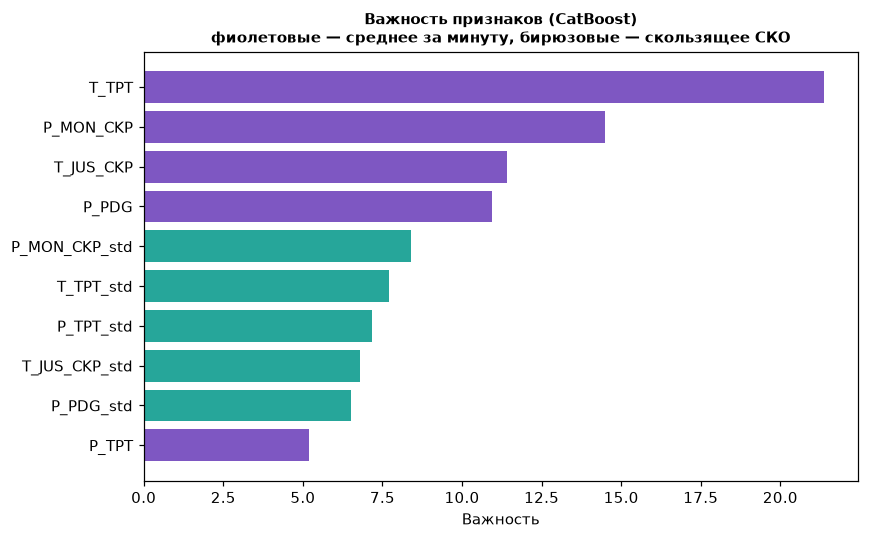

Суммарный вклад признаков-СКО: 36.6%
Топ-5: T_TPT, P_MON_CKP, T_JUS_CKP, P_PDG, P_MON_CKP_std


In [40]:
best_tree_model = results["CatBoost"]["model"]
fi = best_tree_model.get_feature_importance(type="FeatureImportance")
imp_s = pd.Series(fi / fi.sum() * 100, index=FEATURE_COLS).sort_values(ascending=False)

top = imp_s.head(15)[::-1]

fig, ax = plt.subplots(figsize=(8, 0.35 * len(top) + 1.5))
ax.barh(top.index, top.values, color=["#26A69A" if c.endswith("_std") else "#FFA726" if re.search(r"_d\d+$", c) else "#7E57C2"
                                  for c in top.index])
ax.set_title("Важность признаков (CatBoost)\nфиолетовые — среднее за минуту, бирюзовые — скользящее СКО",
             fontweight="bold", fontsize=10)
ax.set_xlabel("Важность")
plt.tight_layout(); plt.show()

share_std = imp_s[imp_s.index.str.endswith("_std")].sum()
print(f"Суммарный вклад признаков-СКО: {share_std:.1f}%")
print("Топ-5:", ", ".join(imp_s.head(5).index))

## 10. Политика передачи по уровням критичности

| Уровень | Политика передачи | MQTT QoS |
|---|---|---|
| P0 | Агрегация и батчинг, передача при свободном канале | QoS 0 |
| P1 | Обычная очередь, стандартная доставка | QoS 1 |
| P2 | Приоритетная очередь, повышенная частота | QoS 1 |
| P3 | Немедленно, подтверждение + повтор при ошибке | QoS 2 |

Таблица политик задаётся **экспертно** (это правила системы, а не результат обучения). Модель определяет состояние → состояние даёт уровень → уровень даёт политику.

In [47]:
policy = {0: ("QoS 0", "агрегация и батчинг, при свободном канале"),
          1: ("QoS 1", "обычная очередь"),
          2: ("QoS 1", "приоритетная очередь, повышенная частота"),
          3: ("QoS 2", "немедленно, подтверждение + повтор")}

# Примеры: по одному случайному наблюдению каждого уровня из тестовой выборки
rng = np.random.default_rng(7)
print(f"{'Истинный':<18}{'Предсказанный':<18}{'QoS':<7}Политика")
print("-" * 80)
for p in range(4):
    idxs = np.where(y_test == p)[0]
    if len(idxs) == 0:
        continue
    i = rng.choice(idxs)
    pred = int(np.ravel(best_tree_model.predict(X_test[i:i+1]))[0])
    print(f"{PRIORITY_NAMES[p]:<18}{PRIORITY_NAMES[pred]:<18}{policy[pred][0]:<7}{policy[pred][1]}")

# Эффект для канала: доля наблюдений по предсказанным уровням
share = pd.Series(y_pred_best).value_counts(normalize=True).reindex(LABELS).fillna(0)
print("\nДоля предсказанных наблюдений по уровням (тест):")
for p in LABELS:
    print(f"  {PRIORITY_NAMES[p]:<18} {share[p]*100:5.1f}%")
print(f"Можно агрегировать (P0): {share[0]*100:.1f}% данных; "
      f"немедленно передаётся (P3): {share[3]*100:.1f}%")

Истинный          Предсказанный     QoS    Политика
--------------------------------------------------------------------------------
P0 — фоновый      P0 — фоновый      QoS 0  агрегация и батчинг, при свободном канале
P1 — обычный      P1 — обычный      QoS 1  обычная очередь
P2 — повышенный   P2 — повышенный   QoS 1  приоритетная очередь, повышенная частота
P3 — критический  P3 — критический  QoS 2  немедленно, подтверждение + повтор

Доля предсказанных наблюдений по уровням (тест):
  P0 — фоновый        48.5%
  P1 — обычный         6.0%
  P2 — повышенный     26.2%
  P3 — критический    19.3%
Можно агрегировать (P0): 48.5% данных; немедленно передаётся (P3): 19.3%


## 11. Итоги только с ско

In [48]:
best = min(results, key=lambda n: (round(results[n]["missed_p3"], 3), -results[n]["f1_macro"]))
r = results[best]
print("=" * 64)
print("Итоги на тест. выборке (скважины не пересекаются с обучающими):")
print("=" * 64)
print(f"Данные: {len(df):,} минутных наблюдений, {df['file'].nunique()} экземпляров, "
      f"источники: {', '.join(sorted(df['source'].unique()))}")
print(f"Признаков: {len(FEATURE_COLS)} ({len(KEEP)} датчиков + их скользящее СКО)")
print(f"Разделение: по скважинам (train {len(set(groups[train_idx]))} / test {len(set(groups[test_idx]))})")
print()
print(table.round(3).to_string())
print()

print(f"Лучшая модель по критерию (M, затем F1-macro): {best} "
      f"(M={r['missed_p3']*100:.1f}%, F1-macro={r['f1_macro']:.3f}, F1(P3)={r['f1_p3']:.3f}, recall(P3)={r['recall_p3']:.3f})")
print(f"Baseline (Сл) F1(P3)={results['Случайный лес']['f1_p3']:.3f}, "
       f"F1-macro={results['Случайный лес']['f1_macro']:.3f}")
print(f"Прирост F1-macro CatBoost vs random forest: "
      f"{(results[best]['f1_macro'] - results['Случайный лес']['f1_macro'])*100:+.1f} п.п.")

print(f"Доля пропущенных аварий (P3, принятых за P0/P1): {r['missed_p3']*100:.1f}%")
print(f"Признаки-лидеры: {', '.join(imp_s.head(3).index)}")
print("=" * 64)


# Выбор лучшей модели по главному критерию:
# 1. Минимум доли пропущенных аварий (M)
# 2. Максимум F1-macro (при равном M)
best_model_name = min(results, key=lambda n: (round(results[n]["missed_p3"], 3), -results[n]["f1_macro"]))
print(f"Лучшая модель по критерию (M, F1-macro): {best_model_name}")
# Теперь везде, где вы ссылаетесь на 'лучшую' модель, используйте best_model_name

Итоги на тест. выборке (скважины не пересекаются с обучающими):
Данные: 775,325 минутных наблюдений, 1568 экземпляров, источники: DRAWN, SIMULATED, WELL
Признаков: 10 (5 датчиков + их скользящее СКО)
Разделение: по скважинам (train 408 / test 81)

                Accuracy  F1-macro  F1 (P3)  Recall (P3)  Пропущено аварий (P3→P0/P1)
Дерево решений     0.891     0.912    0.962        0.933                        0.007
Случайный лес      0.890     0.918    0.966        0.938                        0.011
CatBoost           0.894     0.920    0.951        0.978                        0.000

Лучшая модель по критерию (M, затем F1-macro): CatBoost (M=0.0%, F1-macro=0.920, F1(P3)=0.951, recall(P3)=0.978)
Baseline (Сл) F1(P3)=0.966, F1-macro=0.918
Прирост F1-macro CatBoost vs random forest: +0.2 п.п.
Доля пропущенных аварий (P3, принятых за P0/P1): 0.0%
Признаки-лидеры: T_TPT, P_MON_CKP, T_JUS_CKP
Лучшая модель по критерию (M, F1-macro): CatBoost
